# NBA Performance Analysis: Comparing 10 All-Time Greats (1985–2025)

This project builds a 56,000+ record NBA dataset covering regular-season and playoff box scores, advanced stats, awards, career highs, and Finals betting odds from 1985–2025. The data comes from downloaded tables, web scraping (BeautifulSoup), and the NBA API. It then uses Python (Pandas, NumPy, scikit-learn, Matplotlib) and SQL (SQLite) to compare 10 all-time great players on efficiency, playoff performance, career longevity, and award history.

**Players:** Michael Jordan, LeBron James, Tim Duncan, Kobe Bryant, Shaquille O'Neal, Hakeem Olajuwon, Stephen Curry, Kevin Durant, Nikola Jokic, Giannis Antetokounmpo

# Video Walkthrough

* https://youtu.be/Eqbboj2MLtA

## Data Sources
*   **Per-game box scores (1985–2025, regular season and playoffs):** https://www.basketball-reference.com/leagues/NBA_{Year}_per_game.html. Raw file: **NBA_1985_2025_MASTER.csv**; cleaned file: **clean_downloaded_box_scores.csv**
*   **Advanced box scores (1985–2025, regular season and playoffs):** https://www.basketball-reference.com/leagues/NBA_{Year}_advanced.html. Raw file: **NBA_1985_2025_adv_MASTER.csv**; cleaned file: **clean_adv_box_scores.csv**
*   **Awards (web scraped):** https://www.basketball-reference.com/awards/awards_{Year}.html. Individual awards with vote share, plus All-NBA, All-Defensive, and All-Rookie teams. Finals MVP votes aren't publicly available, and Clutch Player of the Year began in 2022-23, so both are hardcoded. File: **NBA_Awards_1985_2025.csv**
*   **Career highs (NBA API):** https://pypi.org/project/nba_api/. Single-game career highs for the 10 main players (1-10) plus 25 other notable players (11-35). File: **NBA_Career_Highs_1985_2025.csv**
*   **Finals betting odds (web scraped):** https://www.covers.com/sportsoddshistory/nba-playoffs-series/?y={year}. Pre-series odds for every Finals matchup. File: **nba_finals_series_odds_1985_2025.csv**

# Data Collection and Cleaning

The functions below load, scrape, and clean each dataset before analysis.

## Per-Game Box Scores

In [45]:
def data_parser():
    # load the box score csv file
    df = pd.read_csv("NBA_1985_2025_MASTER.csv", encoding="utf-8", encoding_errors="replace", low_memory=False)

    # delete player-additional column if it exists
    df = df.drop(columns=["Player-additional"], errors="ignore")

    # inconsistency 2: foreign character encoding issues
    # players like Luka Dončić were sometimes encoded incorrectly, which could break filtering and analysis
    # fix_text from ftfy smooths out those encoding errors in the Player column
    if "Player" in df.columns:
        df["Player"] = df["Player"].apply(lambda x: fix_text(str(x)) if pd.notna(x) else x)

    # clean type column spacing
    if "Type" in df.columns:
        df["Type"] = df["Type"].astype(str).str.strip()

    # remove leftover header rows
    if "Player" in df.columns:
        df = df[df["Player"] != "Player"]

    # split regular season and playoff rows if the type column exists
    if "Type" in df.columns:
        regular = df[df["Type"] == "Regular"].reset_index(drop=True)
        playoffs = df[df["Type"] == "Playoffs"].reset_index(drop=True)
    else:
        # if no type column exists, treat everything as regular season
        regular = df.reset_index(drop=True)
        playoffs = pd.DataFrame(columns=df.columns)

    # assign playoff seasons by blocks using Rk restarting at 1
    if not playoffs.empty:
        playoffs["Season"] = pd.Series([None] * len(playoffs), dtype="object")
        current_end_year = 1985
        current_season = f"{current_end_year-1}-{current_end_year}"

        for i in range(len(playoffs)):
            rk_val = pd.to_numeric(playoffs.iloc[i]["Rk"], errors="coerce")
            if i > 0 and pd.notna(rk_val) and int(rk_val) == 1:
                current_end_year += 1
                current_season = f"{current_end_year-1}-{current_end_year}"
            playoffs.at[i, "Season"] = current_season

    # inconsistency 3: multi-team rows like 2TM, 3TM, etc.
    # these appear when a player was traded mid-season, and the dataset includes both a combined row and team-specific rows
    # keep the combined row and skip the extra team rows by using regex to detect the 2TM-style label
    cleaned_rows = []
    i = 0
    n_rows = len(regular)
    while i < n_rows:
        row = regular.iloc[i].copy()
        team = str(row["Team"])
        match = re.match(r"(\d+)TM", team)
        if match:
            n = int(match.group(1))
            end_idx = min(i + 1 + n, n_rows)
            next_rows = regular.iloc[i+1:end_idx]
            teams = next_rows["Team"].dropna().astype(str).tolist()
            if teams:
                row["Team"] = f"{n}TM: {', '.join(teams)}"
            cleaned_rows.append(row)
            i += 1 + n
        else:
            cleaned_rows.append(row)
            i += 1

    # rebuild the cleaned regular season dataframe
    regular_clean = pd.DataFrame(cleaned_rows)

    # combine cleaned regular season rows back with playoff rows
    df = pd.concat([regular_clean, playoffs], ignore_index=True)

    # loop through each row to create a proper season column where still missing
    seasons = []
    current_season = None
    for i, row in df.iterrows():
        val = None

        # keep existing season if already assigned
        if "Season" in df.columns:
            s = row["Season"]
            if pd.notna(s):
                s = str(s).strip()
                if s != "" and s.lower() != "nan" and s != "<NA>":
                    try:
                        year = int(float(s))
                        val = f"{year-1}-{year}"
                    except:
                        val = s

        # otherwise try building the season from season end year
        if val is None and "Season_End_Year" in df.columns:
            end_year = pd.to_numeric(row["Season_End_Year"], errors="coerce")
            if pd.notna(end_year):
                end_year = int(end_year)
                val = f"{end_year-1}-{end_year}"

        # if still missing, reuse the most recent valid season
        if val is None:
            val = current_season

        current_season = val
        seasons.append(val)

    # save cleaned season values back into the dataframe
    df["Season"] = pd.Series(seasons, dtype="string")

    # remove league average rows after season labels have been rebuilt
    if "Player" in df.columns:
        df = df[df["Player"] != "League Average"]

    # inconsistency 1: 3-point percentage and other divide-by-zero errors
    # when attempts are 0, percentages like 3P%, FT%, FG%, and 2P% can become NaN because zero divided by zero is undefined
    # replace those NaN values with 0 only when the corresponding attempts column is 0 so later averages and calculations still work
    for num, pct in [("3PA", "3P%"), ("FTA", "FT%"), ("FGA", "FG%"), ("2PA", "2P%")]:
        if {num, pct}.issubset(df.columns):
            df[num] = pd.to_numeric(df[num], errors="coerce")
            df[pct] = pd.to_numeric(df[pct], errors="coerce")
            df.loc[(df[num] == 0) & (df[pct].isna()), pct] = 0

    # convert common counting stats to integers
    for col in ["Age", "G", "GS"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")

    # keep MP numeric, not integer
    if "MP" in df.columns:
        df["MP"] = pd.to_numeric(df["MP"], errors="coerce")

    # fill missing awards with "No Awards"
    if "Awards" in df.columns:
        df["Awards"] = df["Awards"].fillna("No Awards")

    # move season column to sit right after team
    if "Season" in df.columns and "Team" in df.columns:
        cols = list(df.columns)
        cols.remove("Season")
        cols.insert(cols.index("Team") + 1, "Season")
        df = df[cols]

    # drop season end year now that all rows have a cleaned season value
    df = df.drop(columns=["Season_End_Year"], errors="ignore")

    # save the cleaned dataframe to a csv
    df.to_csv("clean_downloaded_box_scores.csv", index=False)
    return df

############ Function Call ############
data_parser()

,Rk,Player,Age,Team,Season,Pos,G,GS,MP,FG,...,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,Awards,Type
0,1.0,Bernard King,28,NYK,1984-1985,SF,55,55,37.5,12.6,...,3.7,5.8,3.7,1.3,0.3,3.7,3.5,32.9,"MVP-7,AS,NBA1",Regular
1,2.0,Larry Bird,28,BOS,1984-1985,SF,80,77,39.5,11.5,...,8.5,10.5,6.6,1.6,1.2,3.1,2.6,28.7,"MVP-1,AS,NBA1",Regular
2,3.0,Michael Jordan,21,CHI,1984-1985,SG,82,82,38.3,10.2,...,4.5,6.5,5.9,2.4,0.8,3.5,3.5,28.2,"MVP-6,ROY-1,AS,NBA2",Regular
3,4.0,Purvis Short,27,GSW,1984-1985,SF,78,77,39.5,10.5,...,3.1,5.1,3.0,1.5,0.3,3.1,3.3,28.0,MVP-20,Regular
4,5.0,Alex English,31,DEN,1984-1985,SF,81,81,36.1,11.6,...,3.1,5.7,4.2,1.2,0.6,3.1,3.2,27.9,"MVP-12,AS",Regular
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26608,215,Reed Sheppard,20,HOU,2024-2025,PG,3,0,3.3,0,...,0.3,0.3,0.3,0.7,0.3,0.3,0.3,0,No Awards,Playoffs
26609,216,P.J. Tucker,39,NYK,2024-2025,SF,1,0,4.0,0,...,0,0,0,0,0,0,1,0,No Awards,Playoffs
26610,217,Jordan Walsh,20,BOS,2024-2025,PF,5,0,3.0,0,...,0.2,0.2,0.2,0,0,0,0,0,No Awards,Playoffs
26611,218,Cam Whitmore,20,HOU,2024-2025,SF,3,0,1.7,0,...,0.3,0.3,0,0,0,0,0,0,No Awards,Playoffs


## Career Highs (NBA API)

In [44]:
def web_parser1():
    #set players
    player_names = ["Michael Jordan", "LeBron James", "Tim Duncan", "Kobe Bryant", "Shaquille O'Neal", "Hakeem Olajuwon", "Stephen Curry", "Kevin Durant", "Nikola Jokic", "Giannis Antetokounmpo", "Dirk Nowitzki", "Kevin Garnett", "David Robinson", "Karl Malone", "Charles Barkley", "Dwyane Wade", "Chris Paul", "Kawhi Leonard", "James Harden", "Russell Westbrook", "Allen Iverson", "Scottie Pippen", "John Stockton", "Patrick Ewing", "Ray Allen", "Dwight Howard", "Anthony Davis", "Tracy McGrady", "Derrick Rose", "Dennis Rodman", "Chris Bosh", "Luka Doncic", "Shai Gilgeous-Alexander", "Jalen Johnson", "Muggsy Bogues"]

    #load player list
    player_dict = players.get_players()

    #clean names
    def clean_name(name):
        name = fix_text(name)
        name = unicodedata.normalize('NFKD', name)
        name = ''.join(i for i in name if not unicodedata.combining(i))
        return name.lower()

    #get player id
    def get_player_id(name):
        target = clean_name(name)
        for i in player_dict:
            full = clean_name(i['full_name'])
            if full == target:
                return i['id']
            if target in full or full in target:
                return i['id']
        return None

    #store player data
    all_data = []

    #scrape each player
    for name in player_names:
        player_id = get_player_id(name)
        if player_id is None:
            continue

        try:
            career = playercareerstats.PlayerCareerStats(player_id=player_id)
            data = career.get_dict()
            career_highs = None

            #find career highs table
            for i in data['resultSets']:
                if i['name'] == 'CareerHighs':
                    career_highs = i
                    break

            #skip missing tables
            if career_highs is None:
                continue

            #build player dataframe
            df = pd.DataFrame(career_highs['rowSet'], columns=career_highs['headers'])
            df = df[['STAT', 'STAT_VALUE']]
            df = df.drop_duplicates(subset='STAT')
            df_wide = df.set_index('STAT').T
            df_wide = df_wide.loc[:, ~df_wide.columns.duplicated()]
            df_wide['Player'] = name
            all_data.append(df_wide)

            #pause requests
            time.sleep(3)
        except:
            continue

    #combine and save data
    final_df = pd.concat(all_data, ignore_index=True, sort=False)
    cols = ['Player'] + [i for i in final_df.columns if i != 'Player']
    final_df = final_df[cols]
    final_df.to_csv("NBA_Career_Highs_1985_2025.csv", index=False)
    return final_df

############ Function Call ############
web_parser1()

STAT,Player,PTS,REB,OREB,DREB,AST,STL,BLK,FGM,FGA,FG3M,FG3A,FTM,FTA
0,Michael Jordan,69,18,8,14,17,10,6,27,49,7,12,26,27
1,LeBron James,51,20,8,16,16,6,5,20,38,7,12,18,24
2,Tim Duncan,53,27,12,23,11,8,9,19,34,1,2,17,24
3,Kobe Bryant,81,16,8,13,17,7,5,28,50,12,21,23,27
4,Shaquille O'Neal,61,28,14,25,10,5,15,24,40,1,1,19,31
5,Hakeem Olajuwon,49,26,11,19,10,6,10,20,34,1,2,18,20
6,Stephen Curry,50,15,5,12,15,6,3,20,38,9,18,16,16
7,Kevin Durant,25,5,0,5,11,2,3,9,16,1,2,6,6
8,Nikola Jokic,53,22,10,19,17,4,4,20,31,7,11,12,14
9,Giannis Antetokounmpo,64,22,9,19,20,5,7,21,39,5,12,24,32


## Awards (Web Scraping)

In [42]:
def web_parser2():
   import pandas as pd
   import requests
   import time
   import unicodedata
   from io import StringIO
   from ftfy import fix_text
   from bs4 import BeautifulSoup, Comment

   # define the year range and output file
   start_year = 1985
   end_year = 2025
   save_path = "NBA_Awards_1985_2025.csv"

   # lists to store collected data
   all_rows = []
   team_rows = []

   # mapping of Basketball Reference table IDs to readable award names
   award_ids = {"mvp": "MVP", "dpoy": "DPOY", "roy": "ROTY", "smoy": "6MOY", "mip": "MIP"}

   # the first year each award existed
   award_start_years = {"MVP": 1956, "DPOY": 1983, "ROTY": 1953, "6MOY": 1983, "MIP": 1986}

   # mapping of team-based award tables
   team_table_ids = {"leading_all_nba": "All-NBA", "leading_all_defense": "All-Defensive", "leading_all_rookie": "All-Rookie"}
   team_award_cols = list(team_table_ids.values())

   # manually defined Finals MVP winners
   finals_mvp_winners = {1985: "Kareem Abdul-Jabbar", 1986: "Larry Bird", 1987: "Magic Johnson", 1988: "James Worthy", 1989: "Joe Dumars", 1990: "Isiah Thomas", 1991: "Michael Jordan", 1992: "Michael Jordan", 1993: "Michael Jordan", 1994: "Hakeem Olajuwon", 1995: "Hakeem Olajuwon", 1996: "Michael Jordan", 1997: "Michael Jordan", 1998: "Michael Jordan", 1999: "Tim Duncan", 2000: "Shaquille O'Neal", 2001: "Shaquille O'Neal", 2002: "Shaquille O'Neal", 2003: "Tim Duncan", 2004: "Chauncey Billups", 2005: "Tim Duncan", 2006: "Dwyane Wade", 2007: "Tony Parker", 2008: "Paul Pierce", 2009: "Kobe Bryant", 2010: "Kobe Bryant", 2011: "Dirk Nowitzki", 2012: "LeBron James", 2013: "LeBron James", 2014: "Kawhi Leonard", 2015: "Andre Iguodala", 2016: "LeBron James", 2017: "Kevin Durant", 2018: "Kevin Durant", 2019: "Kawhi Leonard", 2020: "LeBron James", 2021: "Giannis Antetokounmpo", 2022: "Stephen Curry", 2023: "Nikola Jokic", 2024: "Jaylen Brown"}

   # manually defined Clutch Player of the Year winners
   cpoy_winners = {2023: "De'Aaron Fox", 2024: "Stephen Curry", 2025: "Jalen Brunson"}

   # create a session to avoid being blocked while scraping
   session = requests.Session()
   session.headers.update({"User-Agent": "Mozilla/5.0"})

   # helper function to clean player names
   def clean_player_name(x):
       x = fix_text(str(x))
       x = unicodedata.normalize("NFKD", x).encode("ascii", "ignore").decode("ascii")
       x = x.replace("*", "").strip()
       return x

   # helper function to find tables, including commented-out ones
   def find_table(soup, table_id):
       table = soup.find("table", id=table_id)
       if table is not None:
           return table

       comments = soup.find_all(string=lambda text: isinstance(text, Comment))
       for comment in comments:
           if table_id in comment:
               comment_soup = BeautifulSoup(comment, "html.parser")
               table = comment_soup.find("table", id=table_id)
               if table is not None:
                   return table
       return None

   # flatten multi-level column headers
   def flatten_columns(df):
       if isinstance(df.columns, pd.MultiIndex):
           flat_cols = []
           for col in df.columns:
               pieces = [str(x).strip() for x in col if str(x).strip() and "Unnamed" not in str(x)]
               flat_cols.append(" ".join(pieces) if pieces else str(col[-1]))
           df.columns = flat_cols
       else:
           df.columns = [str(c).strip() for c in df.columns]
       return df

   # valid team tier labels
   tier_tokens = {"1st", "2nd", "3rd", "1T", "2T", "3T", "First", "Second", "Third"}

   # normalize team labels
   def normalize_tier(raw):
       mapping = {"1st": "1st Team", "2nd": "2nd Team", "3rd": "3rd Team", "1T": "1st Team", "2T": "2nd Team", "3T": "3rd Team", "First": "1st Team", "Second": "2nd Team", "Third": "3rd Team"}
       return mapping.get(str(raw).strip(), str(raw).strip())

   # scrape each season
   for year in range(start_year, end_year + 1):
       season_str = f"{year-1}-{year}"

       try:
           url = f"https://www.basketball-reference.com/awards/awards_{year}.html"
           response = session.get(url, timeout=30)
           response.raise_for_status()
           soup = BeautifulSoup(response.text, "html.parser")
       except Exception:
           time.sleep(3)
           continue

       # individual awards
       for award_id, award_name in award_ids.items():
           table = find_table(soup, award_id)
           if table is None:
               continue

           try:
               df = pd.read_html(StringIO(str(table)))[0]
           except Exception:
               continue

           df = flatten_columns(df)
           player_col = next((col for col in df.columns if "Player" in str(col)), None)
           if player_col is None:
               continue

           df = df.rename(columns={player_col: "Player"})
           df = df[df["Player"] != "Player"]
           df["Player"] = df["Player"].apply(clean_player_name)
           df = df[df["Player"] != ""]
           df["Season"] = season_str
           df["Award"] = award_name
           df["AwardValue"] = "No"

           if len(df) > 0:
               df.loc[df.index[0], "AwardValue"] = "Winner"

           all_rows.append(df[["Player", "Season", "Award", "AwardValue"]])

       # team awards
       for table_id, award_label in team_table_ids.items():
           table = find_table(soup, table_id)
           if table is None:
               continue

           try:
               df_t = pd.read_html(StringIO(str(table)))[0]
           except Exception:
               continue

           df_t = flatten_columns(df_t)
           tier_col = None
           player_col = None

           for col in df_t.columns:
               sample = df_t[col].dropna().astype(str)
               if sample.isin(tier_tokens).any() and tier_col is None:
                   tier_col = col
               if "Player" in str(col) and player_col is None:
                   player_col = col

           if player_col is None or tier_col is None:
               continue

           df_t = df_t.rename(columns={player_col: "Player", tier_col: "Tier"})
           df_t = df_t[df_t["Player"] != "Player"]
           df_t["Player"] = df_t["Player"].apply(clean_player_name)
           df_t = df_t[df_t["Player"] != ""]
           df_t = df_t[df_t["Tier"].astype(str).isin(tier_tokens)]
           df_t["Tier"] = df_t["Tier"].apply(normalize_tier)
           df_t["Season"] = season_str
           df_t["AwardCol"] = award_label

           team_rows.append(df_t[["Player", "Season", "AwardCol", "Tier"]])

       time.sleep(3)

   # combine individual award data
   if all_rows:
       long_df = pd.concat(all_rows, ignore_index=True)
       long_df = long_df.drop_duplicates(subset=["Player", "Season", "Award"])
       wide_df = long_df.pivot_table(index=["Player", "Season"], columns="Award", values="AwardValue", aggfunc="first").reset_index()
       wide_df.columns.name = None
   else:
       wide_df = pd.DataFrame(columns=["Player", "Season"])

   # ensure all award columns exist
   for award_name in award_ids.values():
       if award_name not in wide_df.columns:
           wide_df[award_name] = pd.NA

   # fill missing award values
   if len(wide_df) > 0:
       season_end_years = wide_df["Season"].str.split("-").str[1].astype(int)
       for award_name in award_ids.values():
           start_yr_req = award_start_years[award_name]
           wide_df.loc[season_end_years < start_yr_req, award_name] = "N/A"
           wide_df.loc[(season_end_years >= start_yr_req) & (wide_df[award_name].isna()), award_name] = "No"

   # combine team award data
   if team_rows:
       teams_long = pd.concat(team_rows, ignore_index=True)
       teams_long = teams_long.drop_duplicates(subset=["Player", "Season", "AwardCol"])
       teams_wide = teams_long.pivot_table(index=["Player", "Season"], columns="AwardCol", values="Tier", aggfunc="first").reset_index()
       teams_wide.columns.name = None
   else:
       teams_wide = pd.DataFrame(columns=["Player", "Season"])

   # merge awards and team selections
   final_df = wide_df.merge(teams_wide, on=["Player", "Season"], how="outer")

   # add Finals MVP rows
   fmvp_rows = pd.DataFrame({"Player": [clean_player_name(player) for year, player in finals_mvp_winners.items()], "Season": [f"{year-1}-{year}" for year, player in finals_mvp_winners.items()]})

   final_df["Player"] = final_df["Player"].apply(clean_player_name)
   final_df["Season"] = final_df["Season"].astype(str)

   final_df = pd.concat([final_df, fmvp_rows], ignore_index=True)
   final_df = final_df.drop_duplicates(subset=["Player", "Season"], keep="first")

   # fill missing team selections
   for col in team_award_cols:
       if col not in final_df.columns:
           final_df[col] = pd.NA
       final_df[col] = final_df[col].fillna("No")

   # final cleanup for awards
   season_end_years = final_df["Season"].str.split("-").str[1].astype(int)

   for award_name in award_ids.values():
       if award_name not in final_df.columns:
           final_df[award_name] = pd.NA
       start_yr_req = award_start_years[award_name]
       final_df.loc[season_end_years < start_yr_req, award_name] = "N/A"
       final_df.loc[(season_end_years >= start_yr_req) & (final_df[award_name].isna()), award_name] = "No"

   # assign Clutch Player of the Year values
   def cpoy_value(row):
       year = int(row["Season"].split("-")[1])
       player = clean_player_name(row["Player"])

       if year < 2023:
           return "N/A"

       winner = cpoy_winners.get(year)
       if winner is None:
           return "N/A"

       return "Winner" if player == clean_player_name(winner) else "No"

   final_df["CPOY"] = final_df.apply(cpoy_value, axis=1)

   # assign Finals MVP values
   final_df["Finals MVP"] = final_df.apply(lambda row: "Winner" if clean_player_name(row["Player"]) == clean_player_name(finals_mvp_winners.get(int(row["Season"].split("-")[1]), "")) else "No", axis=1)

   # reorder columns and save
   col_order = ["Player", "Season"] + list(award_ids.values()) + ["CPOY", "Finals MVP"] + team_award_cols
   final_df = final_df[[c for c in col_order if c in final_df.columns]]

   final_df = final_df.sort_values(by=["Season", "Player"]).reset_index(drop=True)
   final_df.to_csv(save_path, index=False)

   return final_df
    
############ Function Call ############
web_parser2()

,Player,Season,MVP,DPOY,ROTY,6MOY,MIP,CPOY,Finals MVP,All-NBA,All-Defensive,All-Rookie
0,Alex English,1984-1985,No,No,No,No,N/A,N/A,No,No,No,No
1,Andrew Toney,1984-1985,No,No,No,No,N/A,N/A,No,No,No,No
2,Bernard King,1984-1985,No,No,No,No,N/A,N/A,No,1st Team,No,No
3,Bob McAdoo,1984-1985,No,No,No,No,N/A,N/A,No,No,No,No
4,Bobby Jones,1984-1985,No,No,No,No,N/A,N/A,No,No,2nd Team,No
...,...,...,...,...,...,...,...,...,...,...,...,...
2524,Tyler Herro,2024-2025,No,No,No,No,No,No,No,No,No,No
2525,Tyrese Haliburton,2024-2025,No,No,No,No,No,No,No,3rd Team,No,No
2526,Yves Missi,2024-2025,No,No,No,No,No,No,No,No,No,2nd Team
2527,Zaccharie Risacher,2024-2025,No,No,No,No,No,No,No,No,No,1st Team


# Additional Datasets: Advanced Stats and Finals Odds

In [38]:
def extra_source1():
   # load the advanced stats dataset (low_memory just avoids warnings)
   df = pd.read_csv("NBA_1985_2025_adv_MASTER.csv", encoding="utf-8", encoding_errors="replace", low_memory=False)

   # drop extra player column if it exists (not needed for analysis)
   df = df.drop(columns=["Player-additional"], errors="ignore")

   # fix weird name encoding issues (ex: accents or broken characters)
   if "Player" in df.columns:
       df["Player"] = df["Player"].apply(lambda x: fix_text(str(x)) if pd.notna(x) else x)

   # clean up spacing in the Type column
   if "Type" in df.columns:
       df["Type"] = df["Type"].astype(str).str.strip()

   # make sure Season column can store string values
   if "Season" in df.columns:
       df["Season"] = df["Season"].astype("object")
   else:
       df["Season"] = pd.Series([None] * len(df), dtype="object")

   # assign playoff seasons by grouping rows between league average markers
   if {"Player", "Type"}.issubset(df.columns):
       playoff_mask = df["Type"] == "Playoffs"
       if playoff_mask.any():
           playoff_start_idx = df[playoff_mask].index[0]
           current_end_year = 1985
           current_season = f"{current_end_year-1}-{current_end_year}"

           for i in range(playoff_start_idx, len(df)):
               df.at[i, "Season"] = current_season
               if str(df.at[i, "Type"]).strip() == "Playoffs" and str(df.at[i, "Player"]).strip() == "League Average":
                   current_end_year += 1
                   current_season = f"{current_end_year-1}-{current_end_year}"

   # remove any leftover header rows that got included in the data
   if "Player" in df.columns:
       df = df[df["Player"] != "Player"]

   # split into regular season and playoff data
   if "Type" in df.columns:
       regular = df[df["Type"] == "Regular"].reset_index(drop=True)
       playoffs = df[df["Type"] == "Playoffs"].reset_index(drop=True)
   else:
       # fallback if Type column is missing
       regular = df.reset_index(drop=True)
       playoffs = pd.DataFrame(columns=df.columns)

   # handle multi-team rows (like "2TM", "3TM") by combining team info
   cleaned_rows = []
   i = 0
   n_rows = len(regular)
   while i < n_rows:
       row = regular.iloc[i].copy()
       team = str(row["Team"])

       match = re.match(r"(\d+)TM", team)
       if match:
           n = int(match.group(1))
           end_idx = min(i + 1 + n, n_rows)
           next_rows = regular.iloc[i+1:end_idx]

           teams = next_rows["Team"].dropna().astype(str).tolist()
           if teams:
               row["Team"] = f"{n}TM: {', '.join(teams)}"

           cleaned_rows.append(row)
           i += 1 + n
       else:
           cleaned_rows.append(row)
           i += 1

   # rebuild cleaned regular season dataframe
   regular_clean = pd.DataFrame(cleaned_rows)

   # combine regular and playoff data back together
   df = pd.concat([regular_clean, playoffs], ignore_index=True)

   # rebuild the Season column where values are missing or inconsistent
   seasons = []
   current_season = None
   for i, row in df.iterrows():
       val = None

       # use existing season if valid
       if "Season" in df.columns:
           s = row["Season"]
           if pd.notna(s):
               s = str(s).strip()
               if s != "" and s.lower() != "nan":
                   try:
                       year = int(float(s))
                       val = f"{year-1}-{year}"
                   except:
                       val = s

       # otherwise try building from season end year
       if val is None and "Season_End_Year" in df.columns:
           end_year = pd.to_numeric(row["Season_End_Year"], errors="coerce")
           if pd.notna(end_year):
               end_year = int(end_year)
               val = f"{end_year-1}-{end_year}"

       # fallback: reuse last known season
       if val is None:
           val = current_season

       current_season = val
       seasons.append(val)

   df["Season"] = pd.Series(seasons, dtype="string")

   # remove league average rows (not actual players)
   if "Player" in df.columns:
       df = df[df["Player"] != "League Average"]

   # fix percentage stats where attempts = 0 (avoid NaN from divide-by-zero)
   for num, pct in [("3PA", "3P%"), ("FTA", "FT%"), ("FGA", "FG%"), ("2PA", "2P%")]:
       if {num, pct}.issubset(df.columns):
           df[num] = pd.to_numeric(df[num], errors="coerce")
           df[pct] = pd.to_numeric(df[pct], errors="coerce")
           df.loc[(df[num] == 0) & (df[pct].isna()), pct] = 0

   # convert common counting stats to integers
   for col in ["Age", "G", "GS"]:
       if col in df.columns:
           df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")

   # keep minutes played as numeric (not integer)
   if "MP" in df.columns:
       df["MP"] = pd.to_numeric(df["MP"], errors="coerce")

   # fill missing award values
   if "Awards" in df.columns:
       df["Awards"] = df["Awards"].fillna("No Awards")

   # move Season column next to Team for better organization
   if "Season" in df.columns and "Team" in df.columns:
       cols = list(df.columns)
       cols.remove("Season")
       cols.insert(cols.index("Team") + 1, "Season")
       df = df[cols]

   # drop Season_End_Year since it's no longer needed
   df = df.drop(columns=["Season_End_Year"], errors="ignore")

   # save cleaned dataset
   df.to_csv("clean_adv_box_scores.csv", index=False)
   return df
############ Function Call ############
extra_source1()

,Rk,Player,Age,Team,Season,Pos,G,GS,MP,PER,...,OWS,DWS,WS,WS/48,OBPM,DBPM,BPM,VORP,Awards,Type
0,1.0,Buck Williams,24,NJN,1984-1985,PF,82,82,3182.0,16.7,...,3.7,4.0,7.7,0.116,0.4,-0.6,-0.3,1.4,No Awards,Regular
1,2.0,Larry Bird,28,BOS,1984-1985,SF,80,77,3161.0,26.5,...,10.5,5.2,15.7,0.238,6.8,2.0,8.8,8.7,"MVP-1,AS,NBA1",Regular
2,3.0,Michael Jordan,21,CHI,1984-1985,SG,82,82,3144.0,25.8,...,10.3,3.7,14.0,0.213,5.8,1.5,7.3,7.4,"MVP-6,ROY-1,AS,NBA2",Regular
3,4.0,Michael Ray Richardson,29,NJN,1984-1985,PG,82,82,3127.0,19.8,...,4.5,4.2,8.7,0.134,2.5,1.6,4.1,4.8,"MVP-14,DPOY-7,AS",Regular
4,5.0,Isiah Thomas,23,DET,1984-1985,PG,81,81,3089.0,22.2,...,7.5,3.6,11.2,0.173,5.1,1.2,6.3,6.5,"MVP-9,AS,NBA1",Regular
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26609,215,Alex Len,31,LAL,2024-2025,C,2,0,4.0,23.2,...,0,0,0,0.167,7.9,-16.4,-8.5,0,No Awards,Playoffs
26610,216,Shake Milton,28,LAL,2024-2025,SG,2,0,4.0,-13.9,...,0,0,0,-0.303,-19.8,-6.3,-26.1,0,No Awards,Playoffs
26611,217,Jett Howard,21,ORL,2024-2025,SF,1,0,4.0,61.8,...,0,0,0,0.319,38.1,9.4,47.5,0,No Awards,Playoffs
26612,218,Patty Mills,36,LAC,2024-2025,PG,1,0,4.0,4.6,...,0,0,0,-0.227,-4.6,-2.9,-7.5,0,No Awards,Playoffs


In [37]:
def finals_odds():
    import pandas as pd
    import requests
    from io import StringIO

    #store finals rows
    rows = []
    headers = {"User-Agent": "Mozilla/5.0"}

    #scrape each year
    for year in range(1985, 2026):
        url = f"https://www.covers.com/sportsoddshistory/nba-playoffs-series/?y={year}"
        try:
            response = requests.get(url, headers=headers, timeout=20)
            response.raise_for_status()
            tables = pd.read_html(StringIO(response.text))
            finals_df = None

            #find Finals table
            for i in tables:
                cols = [str(col).strip() for col in i.columns]
                if "Round" in cols and "Winning Team" in cols:
                    temp = i.copy()
                    temp.columns = cols
                    temp["Round"] = temp["Round"].astype(str).str.strip()
                    temp = temp[temp["Round"].str.contains("NBA Finals", case=False, na=False)]
                    if not temp.empty:
                        finals_df = temp
                        break

            #skip years with no Finals row
            if finals_df is None or finals_df.empty:
                continue

            #store Finals matchup
            for i, row in finals_df.iterrows():
                rows.append({"Year": year, "Home_Court_Team": row.get("Team with home-court (seed)"), "Home_Court_Team_Odds": row.get("Team with home-court odds"), "Away_Court_Team": row.get("Team w/o home-court (seed)"), "Away_Court_Team_Odds": row.get("Team w/o home-court odds"), "Winning_Team": row.get("Winning Team")})

        except:
            continue

    #build dataframe
    finals_odds_df = pd.DataFrame(rows)

    #clean team names
    finals_odds_df["Home_Court_Team"] = finals_odds_df["Home_Court_Team"].astype(str).str.replace(r"\s*\(\d+\)", "", regex=True).str.strip()
    finals_odds_df["Away_Court_Team"] = finals_odds_df["Away_Court_Team"].astype(str).str.replace(r"\s*\(\d+\)", "", regex=True).str.strip()

    #order and save columns
    finals_odds_df = finals_odds_df[["Year", "Home_Court_Team", "Home_Court_Team_Odds", "Away_Court_Team", "Away_Court_Team_Odds", "Winning_Team"]]
    finals_odds_df.to_csv("nba_finals_series_odds_1985_2025.csv", index=False)
    return finals_odds_df

############ Function Call ############
finals_odds()

,Year,Home_Court_Team,Home_Court_Team_Odds,Away_Court_Team,Away_Court_Team_Odds,Winning_Team
0,1985,Boston Celtics,170.0,Los Angeles Lakers,-200.0,Los Angeles Lakers
1,1986,Boston Celtics,-700.0,Houston Rockets,500.0,Boston Celtics
2,1987,Los Angeles Lakers,-600.0,Boston Celtics,400.0,Los Angeles Lakers
3,1988,Los Angeles Lakers,-260.0,Detroit Pistons,210.0,Los Angeles Lakers
4,1989,Detroit Pistons,100.0,Los Angeles Lakers,-120.0,Detroit Pistons
5,1990,Detroit Pistons,-400.0,Portland Trail Blazers,300.0,Detroit Pistons
6,1991,Chicago Bulls,-200.0,Los Angeles Lakers,170.0,Chicago Bulls
7,1992,Chicago Bulls,-250.0,Portland Trail Blazers,200.0,Chicago Bulls
8,1993,Phoenix Suns,190.0,Chicago Bulls,-240.0,Chicago Bulls
9,1994,Houston Rockets,-220.0,New York Knicks,180.0,Houston Rockets


# Data Quality Issues and Fixes

1. 3-point percentage and other divide-by-zero errors; we identified this via looking at 3-point attempted values, and given zero divided by zero is undefined, the program output NaN. Trying to calculate league averages and other critical statistics wouldn’t be possible with NaN columns, so we handled it by using pandas’ ifnan method to turn all NaN values to 0.

2. Foreign character encoding issues; for players like Luka Dončić, their names were encoded incorrectly (for instance, with Dončić, his name was encoded as “Luka DonÃ„ÂiÃ„â€¡”). We identified this by observing the player names column and noticing said encoding errors. We handled it via importing Python’s ftfy library and smoothing out the errors using the fix_text function.

3. If a player was traded mid-season, the dataset includes an additional unnecessary row, one of which is the "2TM" (Times Traded) column (with the number changing based on the times traded), representing the combined season totals. The additional rows show the player’s partial stats for each team they played on during the season. We addressed the issue by filtering out the team-specific rows (using regex to find 2TM columns) and keeping the 2TM row.


# Data Analysis

The analysis below covers six insights and four visualizations. It uses multi-dataset joins, minutes-weighted aggregation, position-adjusted z-scores, K-Means clustering of career phases, a K-Nearest Neighbors classifier, and linear regression. A SQL section at the end answers several of the same questions in SQLite.

# Topic Summary

This project asks who the most dominant NBA player of the last 40 years is, and what "dominant" really means. It compares 10 all-time greats on regular-season vs. playoff efficiency (TS%), the difficulty of the Finals they played in (based on betting odds), how their impact (BPM) changed with age, and how their production compared with other players at their position in the same season. It also tests whether MVP, DPOY, and Finals MVP voting actually rewarded the statistically best player. Fewer than half of MVPs and about 37% of DPOYs went to the statistical leader, compared with about 59% of Finals MVPs. Overall, Jordan shows the highest peak and LeBron the strongest longevity.

## Insights

In [6]:
import os
import requests
import re
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from ftfy import fix_text
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import time
import unicodedata
from bs4 import BeautifulSoup, Comment
from io import StringIO
from nba_api.stats.endpoints import teamgamelog, playercareerstats
from nba_api.stats.static import players

### Insight 1 Explanation

Our first insight shows the difference between players' True Shooting Percentage (TS%) in the regular season vs the playoffs. TS% is calculated as: $$
TS\% = \frac{PTS}{2 \cdot (FGA + 0.44 \cdot FTA)}
$$
TS% is often used as the most accurate stat to estimate scoring efficiency; FG% values 2 and 3 pointers the same, eFG% values 3 pointers as a higher risk, higher reward shot, while TS% involves the calculations of eFG% in addition to Free Throws. The goal of this insight is to show which players "rise to the occasion" of the playoffs, and which players let the nerves get to them. In the GOAT debates between Michael Jordan and LeBron, LeBron is often labeled as a "playoff-choker" due to his 4-6 finals record, compared to Michael Jordan's 6-0 record. Overall, while this data shows that Jordan "rises to the occasion", improving his TS% by around .9%, still overall, Lebron on average has a higher TS%, meaning higher efficiency.

In [35]:
def insight1():
    df = pd.read_csv("clean_adv_box_scores.csv")

    selected_players = ["Michael Jordan", "LeBron James", "Tim Duncan", "Kobe Bryant", "Shaquille O'Neal", "Hakeem Olajuwon", "Stephen Curry", "Kevin Durant", "Nikola Jokic", "Giannis Antetokounmpo"]

    df = df[['Player', 'Type', 'TS%']]
    df['Player'] = df['Player'].astype(str).str.strip()
    df['Type'] = df['Type'].astype(str).str.strip()
    df['TS%'] = pd.to_numeric(df['TS%'], errors='coerce')

    df = df[df['Player'].isin(selected_players)]
    df = df[df['Type'].isin(['Regular', 'Playoffs'])]
    df = df.dropna(subset=['TS%'])

    grouped = df.groupby(['Player', 'Type'])['TS%'].mean().unstack()
    grouped = grouped.dropna(subset=['Regular', 'Playoffs'])
    grouped = grouped.reindex([player for player in selected_players if player in grouped.index])

    grouped['Difference'] = grouped['Playoffs'].round(3) - grouped['Regular'].round(3)
    grouped = grouped.sort_values('Difference', ascending=False)

    # Round values to 3 decimal places
    grouped['Regular'] = grouped['Regular'].round(3)
    grouped['Playoffs'] = grouped['Playoffs'].round(3)
    grouped['Difference'] = grouped['Difference'].round(3)
    grouped = grouped[['Regular', 'Playoffs', 'Difference']]

    grouped.to_csv("insight1_output.csv")
    plt.show()

    return grouped
############ Function Call ############
insight1()

Type,Regular,Playoffs,Difference
Player,,,
Hakeem Olajuwon,0.546,0.557,0.011
Michael Jordan,0.559,0.568,0.009
Tim Duncan,0.548,0.546,-0.002
LeBron James,0.592,0.588,-0.004
Kobe Bryant,0.543,0.539,-0.004
Stephen Curry,0.620,0.607,-0.013
Kevin Durant,0.625,0.597,-0.028
Giannis Antetokounmpo,0.603,0.569,-0.034
Shaquille O'Neal,0.588,0.543,-0.045


### Insight 2 Explanation

This insight answers the question of “How hard was it for each player to win the respective finals that they played in? Who has had the hardest finals?” By taking data on sportsbook betting odds prior to these games, we calculated the difficulty of each of the finals games that these 10 players partook in. The difficulty of the finals opponent carries significant weight in the value of the finals win (or the impact of the finals loss), which is far more descriptive than a numerical record for whether someone won or lost. Overall, LeBron on average faced much harder competition; in fact, Michael Jordan's toughest finals opponent was less than the average caliber of the opponents that LeBron faced

In [34]:
def insight2():
   import pandas as pd
   import numpy as np

   # players we are analyzing
   players = ["Michael Jordan", "LeBron James", "Tim Duncan", "Kobe Bryant", "Shaquille O'Neal", "Hakeem Olajuwon", "Stephen Curry", "Kevin Durant", "Nikola Jokic", "Giannis Antetokounmpo"]

   # fix inconsistent team names so everything matches
   fixes = {"LA Lakers": "Los Angeles Lakers", "L.A. Lakers": "Los Angeles Lakers", "N.J. Nets": "New Jersey Nets", "NJ Nets": "New Jersey Nets", "OKC Thunder": "Oklahoma City Thunder", "GS Warriors": "Golden State Warriors", "Golden State": "Golden State Warriors", "Cleveland": "Cleveland Cavaliers", "Miami": "Miami Heat", "San Antonio": "San Antonio Spurs", "Houston": "Houston Rockets", "Chicago": "Chicago Bulls", "Orlando": "Orlando Magic", "Milwaukee": "Milwaukee Bucks", "Denver": "Denver Nuggets", "Phoenix": "Phoenix Suns"}

   # manually map each player to their Finals appearances and teams
   finals_map = {
       "Michael Jordan": {1991:"Chicago Bulls",1992:"Chicago Bulls",1993:"Chicago Bulls",1996:"Chicago Bulls",1997:"Chicago Bulls",1998:"Chicago Bulls"},
       "LeBron James": {2007:"Cleveland Cavaliers",2011:"Miami Heat",2012:"Miami Heat",2013:"Miami Heat",2014:"Miami Heat",2015:"Cleveland Cavaliers",2016:"Cleveland Cavaliers",2017:"Cleveland Cavaliers",2018:"Cleveland Cavaliers",2020:"Los Angeles Lakers"},
       "Tim Duncan": {1999:"San Antonio Spurs",2003:"San Antonio Spurs",2005:"San Antonio Spurs",2007:"San Antonio Spurs",2013:"San Antonio Spurs",2014:"San Antonio Spurs"},
       "Kobe Bryant": {2000:"Los Angeles Lakers",2001:"Los Angeles Lakers",2002:"Los Angeles Lakers",2004:"Los Angeles Lakers",2008:"Los Angeles Lakers",2009:"Los Angeles Lakers",2010:"Los Angeles Lakers"},
       "Shaquille O'Neal": {1995:"Orlando Magic",2000:"Los Angeles Lakers",2001:"Los Angeles Lakers",2002:"Los Angeles Lakers",2004:"Los Angeles Lakers",2006:"Miami Heat"},
       "Hakeem Olajuwon": {1986:"Houston Rockets",1994:"Houston Rockets",1995:"Houston Rockets"},
       "Stephen Curry": {2015:"Golden State Warriors",2016:"Golden State Warriors",2017:"Golden State Warriors",2018:"Golden State Warriors",2019:"Golden State Warriors",2022:"Golden State Warriors"},
       "Kevin Durant": {2012:"Oklahoma City Thunder",2017:"Golden State Warriors",2018:"Golden State Warriors"},
       "Nikola Jokic": {2023:"Denver Nuggets"},
       "Giannis Antetokounmpo": {2021:"Milwaukee Bucks"}}

   # helper to clean team names
   clean = lambda x: fixes.get(str(x).strip(), str(x).strip())

   # convert betting odds into implied probability
   prob = lambda o: np.nan if pd.isna(o) else (100 / (o + 100) if o > 0 else abs(o) / (abs(o) + 100))

   # load finals odds dataset
   df = pd.read_csv("nba_finals_series_odds_1985_2025.csv")

   # clean team names
   for c in ["Home_Court_Team", "Away_Court_Team", "Winning_Team"]:
       df[c] = df[c].apply(clean)

   # convert odds columns to numeric
   for c in ["Home_Court_Team_Odds", "Away_Court_Team_Odds"]:
       df[c] = pd.to_numeric(df[c].astype(str).str.replace("+", "", regex=False).str.strip(), errors="coerce")

   # compute implied probabilities
   df["Home_Prob"] = df["Home_Court_Team_Odds"].apply(prob)
   df["Away_Prob"] = df["Away_Court_Team_Odds"].apply(prob)

   # build detailed dataset of each Finals matchup for each player
   rows = []
   for player in players:
       for year, team in finals_map[player].items():
           temp = df[df["Year"] == year]
           if temp.empty:
               continue

           r = temp.iloc[0]

           # figure out if player was home or away team
           if r["Home_Court_Team"] == team:
               p_team = r["Home_Court_Team"]
               opp = r["Away_Court_Team"]
               p_prob = r["Home_Prob"]
           elif r["Away_Court_Team"] == team:
               p_team = r["Away_Court_Team"]
               opp = r["Home_Court_Team"]
               p_prob = r["Away_Prob"]
           else:
               continue

           # store matchup info
           rows.append({"Player": player, "Year": year, "Player_Team": p_team, "Opponent_Team": opp, "Player_Implied_Prob": round(p_prob, 3), "Matchup_Difficulty": round(1 - p_prob, 3), "Won_Title": "Yes" if r["Winning_Team"] == p_team else "No"})

   # create detailed dataframe
   detail_df = pd.DataFrame(rows).sort_values(["Player", "Year"]).reset_index(drop=True)

   # build summary statistics for each player
   summary = []
   for player in players:
       temp = detail_df[detail_df["Player"] == player]

       all_diff = pd.to_numeric(temp["Matchup_Difficulty"], errors="coerce")
       win_diff = pd.to_numeric(temp.loc[temp["Won_Title"] == "Yes", "Matchup_Difficulty"], errors="coerce")

       hardest = temp.loc[temp["Matchup_Difficulty"].idxmax()] if len(temp) else None

       summary.append({"Player": player, "Finals_Appearances": len(temp), "Finals_Wins": int((temp["Won_Title"] == "Yes").sum()), "Average_Finals_Difficulty": round(all_diff.mean(), 3) if len(temp) else np.nan,"Average_Title_Difficulty": round(win_diff.mean(), 3) if len(win_diff) else np.nan,
           "Hardest_Finals_Year": int(hardest["Year"]) if hardest is not None else np.nan,
           "Hardest_Finals_Opponent": hardest["Opponent_Team"] if hardest is not None else np.nan,
           "Hardest_Finals_Difficulty": round(hardest["Matchup_Difficulty"], 3) if hardest is not None else np.nan
       })

   # final summary table sorted by difficulty and success
   summary_df = pd.DataFrame(summary).sort_values(
       ["Average_Title_Difficulty", "Average_Finals_Difficulty", "Finals_Wins"],
       ascending=[False, False, False]).reset_index(drop=True)

   # save outputs
   detail_df.to_csv("insight2_finals_difficulty_detail.csv", index=False)
   summary_df.to_csv("insight2_finals_difficulty_summary.csv", index=False)

   return summary_df
############ Function Call ############
insight2()

,Player,Finals_Appearances,Finals_Wins,Average_Finals_Difficulty,Average_Title_Difficulty,Hardest_Finals_Year,Hardest_Finals_Opponent,Hardest_Finals_Difficulty
0,Giannis Antetokounmpo,1,1,0.615,0.615,2021,Phoenix Suns,0.615
1,LeBron James,10,4,0.575,0.446,2018,Golden State Warriors,0.873
2,Hakeem Olajuwon,3,2,0.570,0.438,1986,Boston Celtics,0.833
3,Michael Jordan,6,6,0.266,0.266,1998,Utah Jazz,0.444
4,Stephen Curry,6,4,0.273,0.264,2022,Boston Celtics,0.408
5,Tim Duncan,6,5,0.306,0.239,2013,Miami Heat,0.643
6,Shaquille O'Neal,6,4,0.228,0.210,2006,Dallas Mavericks,0.565
7,Nikola Jokic,1,1,0.189,0.189,2023,Miami Heat,0.189
8,Kobe Bryant,7,5,0.195,0.177,2008,Boston Celtics,0.357
9,Kevin Durant,3,2,0.233,0.168,2012,Miami Heat,0.364


### Insight 3 Explanation

This insight answers the question “How has age affected player productivity?” We have BPM (per 100 possessions, average contributions of points, with average set to 0) on the y-axis, and player age on the x-axis. This graph demonstrates the fact that many of these great players started in the league at roughly the average player in productivity, and that many of these players productivity has decreased significantly with age. However, one player stands out above the majority of these greats: LeBron. His superior BPM, even at the age of 40, indicates that age hasn’t affected his quality of play as much as it has affected other top players.

In [33]:
def insight3():
   import os

   # limit thread usage to avoid runtime issues
   os.environ["OMP_NUM_THREADS"] = "2"

   import pandas as pd
   import numpy as np
   import matplotlib.pyplot as plt
   from ftfy import fix_text
   from sklearn.preprocessing import StandardScaler
   from sklearn.cluster import KMeans

   # players included in this analysis
   selected_players = ["Michael Jordan", "LeBron James", "Tim Duncan", "Kobe Bryant", "Shaquille O'Neal", "Hakeem Olajuwon", "Stephen Curry", "Kevin Durant", "Nikola Jokic", "Giannis Antetokounmpo"]

   # load cleaned advanced stats data
   df = pd.read_csv("clean_adv_box_scores.csv")

   # clean player names so they match across datasets
   df["Player"] = df["Player"].apply(lambda x: fix_text(str(x)).strip())
   df["Player"] = df["Player"].str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("utf-8").str.strip()

   # fix Jokic spelling so he matches selected_players
   df["Player"] = df["Player"].replace({"Nikola Jokić": "Nikola Jokic"})

   # keep only the columns needed for this analysis
   keep_cols = ["Player", "Season", "Age", "BPM"]
   if "Type" in df.columns:
       keep_cols.append("Type")
   df = df[keep_cols]

   # make sure Age and BPM are numeric
   df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
   df["BPM"] = pd.to_numeric(df["BPM"], errors="coerce")

   # keep only the selected players and valid rows
   df = df[df["Player"].isin(selected_players)].dropna(subset=["Player", "Season", "Age", "BPM"])

   # average BPM for each player-season-age combo
   group_cols = ["Player", "Season", "Age"]
   if "Type" in df.columns:
       group_cols.append("Type")
   df = df.groupby(group_cols, as_index=False, sort=False)["BPM"].mean()

   # use K-Means to find natural career phase boundaries
   scaler = StandardScaler()
   X = scaler.fit_transform(df[["Age", "BPM"]])
   kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
   kmeans.fit(X)

   # convert cluster centers back to original age/BPM scale
   centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=["Age", "BPM"])
   age_bounds = sorted(centers["Age"])
   b1 = (age_bounds[0] + age_bounds[1]) / 2
   b2 = (age_bounds[1] + age_bounds[2]) / 2

   # assign each row to a career phase based on age
   df["Phase"] = np.where(df["Age"] < b1, "Early Career", np.where(df["Age"] < b2, "Prime Years", "Late Career"))

   # preserve the original player order
   df["Player"] = pd.Categorical(df["Player"], categories=selected_players, ordered=True)

   # sort cleanly by player, then age, then season
   sort_cols = ["Player", "Age", "Season"]
   if "Type" in df.columns:
       sort_cols.append("Type")
   df = df.sort_values(sort_cols).reset_index(drop=True)

   # calculate each player's average BPM change per year
   bpm_summary = []
   for player in selected_players:
       p = df[df["Player"] == player].sort_values(sort_cols).copy()
       if len(p) == 0:
           continue

       age_diff = p["Age"].diff()
       bpm_diff = p["BPM"].diff()
       yearly_change = (bpm_diff / age_diff).replace([np.inf, -np.inf], np.nan).dropna()
       avg_change = round(yearly_change.mean(), 3) if len(yearly_change) > 0 else None
       bpm_summary.append([player, avg_change])

   # build summary dataframe in the original player order
   bpm_summary_df = pd.DataFrame(bpm_summary, columns=["Player", "Avg_BPM_Change_Per_Year"])
   bpm_summary_df["Player"] = pd.Categorical(bpm_summary_df["Player"], categories=selected_players, ordered=True)
   bpm_summary_df = bpm_summary_df.sort_values("Player").reset_index(drop=True)

   # convert player column back to normal strings before exporting
   df["Player"] = df["Player"].astype(str)
   bpm_summary_df["Player"] = bpm_summary_df["Player"].astype(str)

   # save both outputs
   df.to_csv("insight3_career_phases.csv", index=False)
   bpm_summary_df.to_csv("insight3_bpm_change_summary.csv", index=False)
   return df

############ Function Call ############
insight3()

,Player,Season,Age,Type,BPM,Phase
0,Michael Jordan,1984-1985,21.0,Playoffs,9.5,Early Career
1,Michael Jordan,1984-1985,21.0,Regular,7.3,Early Career
2,Michael Jordan,1985-1986,22.0,Playoffs,11.9,Early Career
3,Michael Jordan,1985-1986,22.0,Regular,9.7,Early Career
4,Michael Jordan,1986-1987,23.0,Playoffs,12.7,Early Career
...,...,...,...,...,...,...
298,Giannis Antetokounmpo,2022-2023,28.0,Playoffs,2.0,Prime Years
299,Giannis Antetokounmpo,2022-2023,28.0,Regular,8.5,Prime Years
300,Giannis Antetokounmpo,2023-2024,29.0,Regular,9.0,Prime Years
301,Giannis Antetokounmpo,2024-2025,30.0,Playoffs,11.4,Prime Years


### Insight 4 Explanation

This insight answers the question “Were the players who won the MVP, DPOY, and FMVP awards statistically the best players?” This is an extremely important question because, from a data-analysis perspective, player statistics are among the only ways to assess a player's impact and strength. Our data indicates that slightly less than half of MVP award winners were statistically the best players for the award, while about 59% of FMVP winners and about 37% of DPOY winners were statistically the best players for their awards. Different sources of voter bias can affect these statistics: if a voter has voted MVP in previous seasons, he is less likely to vote for that player again due to voter fatigue. Additionally, there are no strong statistics to fully prove defensive efficiency; it is more subjective, which can help explain the lower DPOY accuracy. Finally, for Finals MVP, the award is heavily tied to team success, since nearly every winner has come from the winning team, with Jerry West in 1969 being the only exception.

In [32]:
def insight4():
    #map team names
    ALIAS_MAP = {'ATL':'Atlanta Hawks','BOS':'Boston Celtics','BRK':'Brooklyn Nets','BKN':'Brooklyn Nets','CHA':'Charlotte Hornets','CHH':'Charlotte Hornets','CHI':'Chicago Bulls','CLE':'Cleveland Cavaliers','DAL':'Dallas Mavericks','DEN':'Denver Nuggets','DET':'Detroit Pistons','GSW':'Golden State Warriors','HOU':'Houston Rockets','IND':'Indiana Pacers','LAC':'Los Angeles Clippers','LAL':'Los Angeles Lakers','MEM':'Memphis Grizzlies','MIA':'Miami Heat','MIL':'Milwaukee Bucks','MIN':'Minnesota Timberwolves','NOP':'New Orleans Pelicans','NOH':'New Orleans Hornets','NOK':'New Orleans Hornets','NJN':'New Jersey Nets','NYK':'New York Knicks','OKC':'Oklahoma City Thunder','ORL':'Orlando Magic','PHI':'Philadelphia 76ers','PHO':'Phoenix Suns','PHX':'Phoenix Suns','POR':'Portland Trail Blazers','SAC':'Sacramento Kings','SAS':'San Antonio Spurs','SEA':'Seattle SuperSonics','TOR':'Toronto Raptors','UTA':'Utah Jazz','UTH':'Utah Jazz','WAS':'Washington Wizards','WSB':'Washington Bullets'}
    shortened_nba_seasons = {'1998-1999': 50, '2011-2012': 66, '2019-2020': 72, '2020-2021': 72}

    #format seasons
    def normalize_season(s):
        s = str(s).strip()
        if re.match(r'^\d{4}-\d{2}$', s):
            start = int(s[:4]); end = (start // 100) * 100 + int(s[-2:])
            if end < start:
                end += 100
            return f"{start}-{end}"
        if re.match(r'^\d{4}$', s):
            y = int(s)
            return f"{y-1}-{y}"
        return s

    #clean dataframe
    def clean_df(df):
        if 'Player' in df.columns:
            df['Player'] = df['Player'].apply(lambda n: unicodedata.normalize('NFKD', str(n).strip()).encode('ascii', 'ignore').decode().strip())
        if 'Season' in df.columns:
            df['Season'] = df['Season'].astype(str).str.strip().apply(normalize_season)
        if 'Date' in df.columns:
            df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
        if 'Team' in df.columns:
            df['Team'] = df['Team'].astype(str).str.strip().apply(lambda t: ALIAS_MAP.get(t, t))
        return df

    #load data
    basic = clean_df(pd.read_csv("clean_downloaded_box_scores.csv", low_memory=False))
    adv = clean_df(pd.read_csv("clean_adv_box_scores.csv", low_memory=False))
    awards = clean_df(pd.read_csv("NBA_Awards_1985_2025.csv", low_memory=False))

    #clean numeric columns
    if 'Rk' in basic.columns:
        basic['Rk'] = pd.to_numeric(basic['Rk'], errors='coerce')
    if 'Rk' in adv.columns:
        adv['Rk'] = pd.to_numeric(adv['Rk'], errors='coerce')

    for col in ['PTS','AST','TRB','STL','BLK','DRB','MP','G']:
        if col in basic.columns:
            basic[col] = pd.to_numeric(basic[col], errors='coerce')

    for col in ['BPM','VORP','WS','WS/48','DBPM']:
        if col in adv.columns:
            adv[col] = pd.to_numeric(adv[col], errors='coerce')

    #split by season type
    def split_type(df, t):
        if 'Type' in df.columns:
            return df[df['Type'].str.strip().str.lower() == t].copy()
        return df.copy()

    basic_reg, adv_reg = split_type(basic, 'regular'), split_type(adv, 'regular')
    basic_play, adv_play = split_type(basic, 'playoffs'), split_type(adv, 'playoffs')

    #define Finals matchups
    finals_raw = [("2024-2025","Oklahoma City Thunder","Indiana Pacers"),("2023-2024","Boston Celtics","Dallas Mavericks"),("2022-2023","Denver Nuggets","Miami Heat"),("2021-2022","Golden State Warriors","Boston Celtics"),("2020-2021","Milwaukee Bucks","Phoenix Suns"),("2019-2020","Los Angeles Lakers","Miami Heat"),("2018-2019","Toronto Raptors","Golden State Warriors"),("2017-2018","Golden State Warriors","Cleveland Cavaliers"),("2016-2017","Golden State Warriors","Cleveland Cavaliers"),("2015-2016","Cleveland Cavaliers","Golden State Warriors"),("2014-2015","Golden State Warriors","Cleveland Cavaliers"),("2013-2014","San Antonio Spurs","Miami Heat"),("2012-2013","Miami Heat","San Antonio Spurs"),("2011-2012","Miami Heat","Oklahoma City Thunder"),("2010-2011","Dallas Mavericks","Miami Heat"),("2009-2010","Los Angeles Lakers","Boston Celtics"),("2008-2009","Los Angeles Lakers","Orlando Magic"),("2007-2008","Boston Celtics","Los Angeles Lakers"),("2006-2007","San Antonio Spurs","Cleveland Cavaliers"),("2005-2006","Miami Heat","Dallas Mavericks"),("2004-2005","San Antonio Spurs","Detroit Pistons"),("2003-2004","Detroit Pistons","Los Angeles Lakers"),("2002-2003","San Antonio Spurs","New Jersey Nets"),("2001-2002","Los Angeles Lakers","New Jersey Nets"),("2000-2001","Los Angeles Lakers","Philadelphia 76ers"),("1999-2000","Los Angeles Lakers","Indiana Pacers"),("1998-1999","San Antonio Spurs","New York Knicks"),("1997-1998","Chicago Bulls","Utah Jazz"),("1996-1997","Chicago Bulls","Utah Jazz"),("1995-1996","Chicago Bulls","Seattle SuperSonics"),("1994-1995","Houston Rockets","Orlando Magic"),("1993-1994","Houston Rockets","New York Knicks"),("1992-1993","Chicago Bulls","Phoenix Suns"),("1991-1992","Chicago Bulls","Portland Trail Blazers"),("1990-1991","Chicago Bulls","Los Angeles Lakers"),("1989-1990","Detroit Pistons","Portland Trail Blazers"),("1988-1989","Detroit Pistons","Los Angeles Lakers"),("1987-1988","Los Angeles Lakers","Detroit Pistons"),("1986-1987","Los Angeles Lakers","Boston Celtics"),("1985-1986","Boston Celtics","Houston Rockets"),("1984-1985","Los Angeles Lakers","Boston Celtics")]
    finals_df = pd.DataFrame(finals_raw, columns=['Season','Finals_Team_1','Finals_Team_2'])
    finals_df['Season'] = finals_df['Season'].apply(normalize_season)
    for col in ['Finals_Team_1','Finals_Team_2']:
        finals_df[col] = finals_df[col].apply(lambda t: ALIAS_MAP.get(t, t))
    full_season_list = sorted(finals_df['Season'].dropna().unique())

    #keep only Finals teams
    def to_finals_only(df):
        if 'Team' not in df.columns:
            return df.iloc[0:0].copy()
        m = df.merge(finals_df, on='Season', how='inner')
        return m[(m['Team'] == m['Finals_Team_1']) | (m['Team'] == m['Finals_Team_2'])].drop(columns=['Finals_Team_1','Finals_Team_2'], errors='ignore')

    basic_finals, adv_finals = to_finals_only(basic_play), to_finals_only(adv_play)

    #aggregate stats
    def agg(df, keep_cols):
        cols = ['Player','Season'] + [c for c in keep_cols if c in df.columns]
        return df[cols].groupby(['Player','Season'], as_index=False).mean()

    basic_reg_g = agg(basic_reg, ['PTS','AST','TRB','STL','BLK','DRB','MP','G'])
    adv_reg_g = agg(adv_reg, ['BPM','VORP','WS','WS/48','DBPM'])
    regular_stats = basic_reg_g.merge(adv_reg_g, on=['Player','Season'], how='left')

    #fix games column
    if 'G_x' in regular_stats.columns:
        g_max = basic_reg[['Player','Season','G']].dropna(subset=['G'])
        g_max['G'] = pd.to_numeric(g_max['G'], errors='coerce')
        g_max = g_max.groupby(['Player','Season'], as_index=False)['G'].max()
        regular_stats = regular_stats.drop(columns=['G_x','G_y'], errors='ignore').merge(g_max, on=['Player','Season'], how='left')

    finals_stats = agg(basic_finals, ['PTS','AST','TRB','STL','BLK','DRB','MP']).merge(agg(adv_finals, ['BPM','VORP','WS','WS/48','DBPM']), on=['Player','Season'], how='left')

    #set eligibility
    regular_stats['Required_Games'] = regular_stats['Season'].apply(lambda s: math.ceil(shortened_nba_seasons.get(s, 82) * (65/82)))
    for col in ['MVP_Eligible','DPOY_Eligible']:
        regular_stats[col] = 0
    if 'G' in regular_stats.columns and 'MP' in regular_stats.columns:
        elig = (regular_stats['G'] >= regular_stats['Required_Games']) & (regular_stats['MP'] >= 20)
        regular_stats.loc[elig, 'MVP_Eligible'] = 1
        regular_stats.loc[elig, 'DPOY_Eligible'] = 1

    finals_stats['FMVP_Eligible'] = 0
    if 'MP' in finals_stats.columns:
        finals_stats.loc[finals_stats['MP'] >= 15, 'FMVP_Eligible'] = 1

    #extract winners
    def extract_winners(col):
        if col not in awards.columns:
            return {}
        sub = awards[awards[col].astype(str).str.strip().str.lower().isin({'yes','winner','won','1','true','y'})]
        return sub.drop_duplicates('Season').set_index('Season')['Player'].to_dict()

    fmvp_col = 'Finals MVP' if 'Finals MVP' in awards.columns else 'FMVP'
    mvp_winners = extract_winners('MVP')
    dpoy_winners = extract_winners('DPOY')
    
    #players who weren't voted for other awards
    fmvp_winners = {**extract_winners(fmvp_col), **{'1987-1988':'James Worthy','2003-2004':'Chauncey Billups','2023-2024':'Jaylen Brown'}}

    #add target column
    def add_targets(df, winner_map):
        df = df.copy()
        df['Target'] = 0
        for season, winner in winner_map.items():
            df.loc[(df['Season'] == season) & (df['Player'] == winner), 'Target'] = 1
        return df

    #set model configs
    award_configs = {'MVP': {'df': add_targets(regular_stats, mvp_winners), 'winner_map': mvp_winners, 'eligible_col': 'MVP_Eligible', 'features': ['PTS','AST','TRB','WS','WS/48','BPM','VORP','MP','G']}, 'DPOY': {'df': add_targets(regular_stats, dpoy_winners), 'winner_map': dpoy_winners, 'eligible_col': 'DPOY_Eligible', 'features': ['STL','BLK','DRB','DBPM','BPM','WS','MP','G']}, 'FMVP': {'df': add_targets(finals_stats, fmvp_winners), 'winner_map': fmvp_winners, 'eligible_col': 'FMVP_Eligible', 'features': ['PTS','AST','TRB','WS/48','BPM','VORP','MP']}}

    #set output structure
    result_columns = ['Award','Season','Predicted_Player','Predicted_Rank','Actual_Winner','Actual_Winner_Rank','Actual_Eligible','Actual_In_Prediction_Pool','Top_1_Hit','Top_3_Hit','Top_5_Hit','Candidate_Count']
    all_rows, summary_rows = [], []

    #score each season
    for award_name, cfg in award_configs.items():
        src = cfg['df']
        winner_map = cfg['winner_map']
        elig_col = cfg['eligible_col']
        feats = [f for f in cfg['features'] if f in src.columns]
        award_rows = []

        for season in full_season_list:
            season_df = src[src['Season'] == season].copy()
            train_df = src[src['Season'] != season].copy()
            actual = winner_map.get(season, 'No recorded winner')

            candidates = season_df[season_df[elig_col] == 1].copy()
            if candidates.empty:
                candidates = season_df.copy()
            if candidates.empty:
                candidates = src[src[elig_col] == 1].copy()
            if candidates.empty:
                candidates = src.copy()

            if 'Target' not in train_df.columns:
                train_df['Target'] = 0
            if 'Target' not in candidates.columns:
                candidates['Target'] = 0
            if train_df['Target'].nunique() < 2:
                train_df = src.copy()

            #fill missing feature values
            for col in feats:
                for df in [train_df, candidates]:
                    if col not in df.columns:
                        df[col] = 0.0
                    df[col] = pd.to_numeric(df[col], errors='coerce')
                fill = train_df[col].median()
                fill = candidates[col].median() if pd.isna(fill) else fill
                fill = 0.0 if pd.isna(fill) else fill
                train_df[col] = train_df[col].fillna(fill)
                candidates[col] = candidates[col].fillna(fill)

            #fit model and rank players
            model = Pipeline([('scaler', StandardScaler()), ('linreg', LinearRegression())])
            model.fit(train_df[feats], train_df['Target'].astype(float))
            candidates['Predicted_Winner_Rating'] = model.predict(candidates[feats])
            candidates = candidates.sort_values(['Predicted_Winner_Rating','Player'], ascending=[False,True]).reset_index(drop=True)
            candidates['Predicted_Rank'] = np.arange(1, len(candidates) + 1)

            #store season result
            pred_player = candidates.iloc[0]['Player']
            in_pool = int(actual in candidates['Player'].values)
            actual_rank = int(candidates[candidates['Player'] == actual].iloc[0]['Predicted_Rank']) if in_pool else None
            actual_elig = int(season_df[season_df['Player'] == actual].iloc[0][elig_col]) if actual != 'No recorded winner' and actual in season_df['Player'].values else 0

            award_rows.append({'Award': award_name, 'Season': season, 'Predicted_Player': pred_player, 'Predicted_Rank': 1, 'Actual_Winner': actual, 'Actual_Winner_Rank': actual_rank, 'Actual_Eligible': actual_elig, 'Actual_In_Prediction_Pool': in_pool, 'Top_1_Hit': int(actual_rank == 1) if actual_rank else 0, 'Top_3_Hit': int(actual_rank is not None and actual_rank <= 3), 'Top_5_Hit': int(actual_rank is not None and actual_rank <= 5), 'Candidate_Count': len(candidates)})

        #save award results
        award_df = pd.DataFrame(award_rows, columns=result_columns)
        award_df.to_csv(f"{award_name.lower()}_season_rank_results.csv", index=False)

        #store summary row
        summary_rows.append({'Award': award_name, 'Seasons_Evaluated': len(award_df), 'Top_1_Hits': int(award_df['Top_1_Hit'].sum()), 'Top_1_Rate': award_df['Top_1_Hit'].mean() if len(award_df) else 0.0, 'Top_3_Hits': int(award_df['Top_3_Hit'].sum()), 'Top_3_Rate': award_df['Top_3_Hit'].mean() if len(award_df) else 0.0, 'Top_5_Hits': int(award_df['Top_5_Hit'].sum()), 'Top_5_Rate': award_df['Top_5_Hit'].mean() if len(award_df) else 0.0, 'Seasons_Actual_Winner_In_Pool': int((award_df['Actual_In_Prediction_Pool'] == 1).sum())})
        all_rows.extend(award_rows)

    #save outputs
    all_results_df = pd.DataFrame(all_rows, columns=result_columns)
    summary_df = pd.DataFrame(summary_rows)
    all_results_df.to_csv("award_rank_season_results.csv", index=False)
    summary_df.to_csv("award_rank_summary.csv", index=False)
    return summary_df

############ Function Call ############
insight4()

,Award,Seasons_Evaluated,Top_1_Hits,Top_1_Rate,Top_3_Hits,Top_3_Rate,Top_5_Hits,Top_5_Rate,Seasons_Actual_Winner_In_Pool
0,MVP,41,20,0.487805,36,0.878049,38,0.926829,41
1,DPOY,41,15,0.365854,21,0.512195,25,0.609756,38
2,FMVP,41,24,0.585366,37,0.902439,39,0.951220,41


### Insight 5 Explanation

This insight answers the question “Which players truly had the most dominant performances relative to their position and season?” This is an extremely important question because raw statistics alone do not always show how impressive a player’s performance was in context. By comparing each player’s averages to the average stats for their position in that same season, our data helps show which players were not just great overall, but were truly separating themselves from their peers at the exact role they played. This matters because a dominant scoring season from a point guard and a dominant rebounding season from a center should not be judged against the same baseline. By using positional season averages, we were able to identify the players whose performances honestly stood out the most compared to what was normal for their position, giving a much clearer picture of dominance across eras and play styles. Through this, we can see that Michael Jordan had more statistically impressive peaks, while LeBron James had more dominance over longer periods.

In [21]:
def make_position_season_averages():
    df = pd.read_csv("clean_downloaded_box_scores.csv", low_memory=False)

    group_cols = ["Season", "Pos", "Type"]

    # drop true missing grouping values first
    df = df.dropna(subset=group_cols).copy()

    # clean grouping columns
    for col in group_cols:
        df[col] = df[col].astype(str).str.strip()

    # remove fake season/type/pos values created from bad rows
    df = df[(df["Season"] != "") & (df["Season"].str.lower() != "nan") & (df["Pos"] != "") & (df["Pos"].str.lower() != "nan") & (df["Type"] != "") & (df["Type"].str.lower() != "nan")].copy()

    # keep only wanted positions and order
    pos_order = ["PG", "SG", "SF", "PF", "C"]
    type_order = ["Regular", "Playoffs"]

    df["Pos"] = df["Pos"].str.upper()
    df["Type"] = df["Type"].str.title()

    df = df[df["Pos"].isin(pos_order)].copy()
    df = df[df["Type"].isin(type_order)].copy()

    # numeric columns
    numeric_cols = df.select_dtypes(include="number").columns.tolist()

    # remove columns you do not want averaged
    for col in ["Rk"]:
        if col in numeric_cols:
            numeric_cols.remove(col)

    # ensure numeric
    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # average by season/position/type
    avg_df = (df.groupby(group_cols)[numeric_cols].mean().reset_index())

    # custom sort
    avg_df["Pos"] = pd.Categorical(avg_df["Pos"], categories=pos_order, ordered=True)
    avg_df["Type"] = pd.Categorical(avg_df["Type"], categories=type_order, ordered=True)

    avg_df = avg_df.sort_values(by=["Season", "Type", "Pos"]).reset_index(drop=True)

    # round values
    avg_df[numeric_cols] = avg_df[numeric_cols].round(3)

    # save new csv
    avg_df.to_csv("position_season_type_averages.csv", index=False)

    return avg_df

############ Function Call ############
make_position_season_averages()

,Season,Pos,Type,Age,G,GS,MP,FG,FGA,FG%,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
0,1984-1985,PG,Regular,26.233,58.067,31.967,22.363,3.428,7.415,0.445,...,0.761,0.578,1.508,2.092,4.715,1.163,0.138,1.785,1.920,8.713
1,1984-1985,SG,Regular,25.429,59.000,28.937,20.825,4.119,8.556,0.462,...,0.775,0.783,1.443,2.229,2.584,0.844,0.202,1.514,1.941,10.238
2,1984-1985,SF,Regular,26.206,57.794,26.809,20.700,4.185,8.768,0.449,...,0.715,1.284,2.160,3.441,1.762,0.703,0.294,1.435,2.068,10.624
3,1984-1985,PF,Regular,25.742,63.355,29.306,21.479,3.645,7.297,0.490,...,0.713,1.819,3.603,5.418,1.371,0.621,0.640,1.610,2.642,9.305
4,1984-1985,C,Regular,27.478,63.134,30.582,20.339,3.166,6.269,0.473,...,0.670,1.700,3.736,5.418,1.158,0.451,0.964,1.493,2.584,8.172
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
405,2024-2025,PG,Playoffs,27.895,7.789,4.316,21.750,3.711,8.618,0.409,...,0.585,0.550,2.179,2.732,3.221,0.676,0.347,1.487,1.868,10.584
406,2024-2025,SG,Playoffs,25.789,9.246,3.211,19.340,2.791,6.668,0.410,...,0.605,0.535,2.042,2.581,1.742,0.639,0.212,0.914,1.512,8.009
407,2024-2025,SF,Playoffs,26.179,7.128,3.923,17.103,2.762,6.195,0.390,...,0.462,0.833,2.038,2.872,1.359,0.536,0.354,0.967,1.426,7.733
408,2024-2025,PF,Playoffs,26.833,8.119,3.452,19.917,3.345,7.117,0.423,...,0.560,0.943,2.976,3.919,1.448,0.562,0.429,1.124,1.590,9.057


In [20]:
def make_adv_position_season_averages():
    #load data
    df = pd.read_csv("clean_adv_box_scores.csv")
    group_cols = ["Season", "Pos", "Type"]
    pos_order = ["PG", "SG", "SF", "PF", "C"]
    type_order = ["Regular", "Playoffs"]

    #clean grouping columns
    df = df.dropna(subset=group_cols).copy()
    for col in group_cols:
        df[col] = df[col].astype(str).str.strip()

    #filter valid rows
    df = df[(df["Season"] != "") & (df["Season"].str.lower() != "nan") & (df["Pos"] != "") & (df["Pos"].str.lower() != "nan") & (df["Type"] != "") & (df["Type"].str.lower() != "nan")].copy()
    df["Pos"] = df["Pos"].str.upper()
    df["Type"] = df["Type"].str.title()
    df = df[df["Pos"].isin(pos_order)].copy()
    df = df[df["Type"].isin(type_order)].copy()

    #get numeric columns
    numeric_cols = df.select_dtypes(include="number").columns.tolist()
    if "Rk" in numeric_cols:
        numeric_cols.remove("Rk")
    for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    #average by season, position, and type
    avg_df = df.groupby(group_cols)[numeric_cols].mean().reset_index()

    #sort output
    avg_df["Pos"] = pd.Categorical(avg_df["Pos"], categories=pos_order, ordered=True)
    avg_df["Type"] = pd.Categorical(avg_df["Type"], categories=type_order, ordered=True)
    avg_df = avg_df.sort_values(by=["Season", "Type", "Pos"]).reset_index(drop=True)

    #round and save
    avg_df[numeric_cols] = avg_df[numeric_cols].round(3)
    avg_df.to_csv("adv_position_season_type_averages.csv", index=False)
    return avg_df

############ Function Call ############
make_adv_position_season_averages()

,Season,Pos,Type,Age,G,GS,MP,PER,TS%,3PAr,...,TOV%,USG%,OWS,DWS,WS,WS/48,OBPM,DBPM,BPM,VORP
0,1984-1985,PG,Regular,26.233,58.067,31.967,1473.433,12.835,0.504,0.080,...,19.280,17.730,1.600,1.390,2.987,0.066,-0.843,0.282,-0.555,1.077
1,1984-1985,SG,Regular,25.429,59.000,28.937,1417.095,12.711,0.512,0.057,...,14.719,21.365,1.578,1.179,2.751,0.056,-1.295,-0.456,-1.754,0.711
2,1984-1985,SF,Regular,26.206,57.794,26.809,1353.441,12.588,0.497,0.033,...,13.844,21.093,1.729,1.260,2.985,0.062,-1.228,-0.690,-1.924,0.787
3,1984-1985,PF,Regular,25.742,63.355,29.306,1477.048,12.673,0.536,0.009,...,17.482,18.018,1.374,1.737,3.105,0.077,-1.673,-0.110,-1.787,0.523
4,1984-1985,C,Regular,27.478,63.134,30.582,1403.672,11.701,0.518,0.004,...,18.899,16.393,1.200,1.785,2.984,0.069,-2.475,0.178,-2.293,0.519
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
405,2024-2025,PG,Playoffs,27.895,7.789,4.316,197.211,13.218,0.524,0.469,...,13.461,20.971,0.282,0.166,0.447,0.060,-0.403,0.711,0.303,0.224
406,2024-2025,SG,Playoffs,25.789,9.246,3.211,200.860,10.382,0.531,0.577,...,11.772,17.588,0.189,0.184,0.384,0.038,-1.758,0.170,-1.591,0.165
407,2024-2025,SF,Playoffs,26.179,7.128,3.923,161.410,12.459,0.513,0.479,...,15.882,20.146,0.144,0.146,0.282,0.005,-0.810,-0.105,-0.905,0.121
408,2024-2025,PF,Playoffs,26.833,8.119,3.452,182.738,12.905,0.546,0.492,...,14.850,18.669,0.190,0.179,0.374,0.060,-0.321,0.702,0.386,0.171


In [6]:
def insight5():
    #load data
    full_df = pd.read_csv("clean_downloaded_box_scores.csv", low_memory=False)
    selected_players = ["Michael Jordan", "LeBron James", "Tim Duncan", "Kobe Bryant", "Shaquille O'Neal", "Hakeem Olajuwon", "Stephen Curry", "Kevin Durant", "Nikola Jokic", "Giannis Antetokounmpo"]
    stats = ["PTS", "TRB", "AST", "BLK", "STL"]
    pos_order = ["PG", "SG", "SF", "PF", "C"]
    group_cols = ["Season", "Pos", "Type"]

    #clean columns
    for col in ["Season", "Pos", "Type", "Player"]:
        if col in full_df.columns:
            full_df[col] = full_df[col].astype(str).str.strip()
    full_df["Player"] = full_df["Player"].replace({"Nikola Jokić": "Nikola Jokic", "Nikola Jokic ": "Nikola Jokic", " Nikola Jokic": "Nikola Jokic"})
    for col in stats:
        full_df[col] = pd.to_numeric(full_df[col], errors="coerce")

    #filter valid rows
    full_df = full_df.dropna(subset=["Season", "Pos", "Type", "Player"]).copy()
    full_df = full_df[(full_df["Season"].str.lower() != "nan") & (full_df["Pos"].str.lower() != "nan") & (full_df["Type"].str.lower() != "nan") & (full_df["Player"].str.lower() != "nan")].copy()
    full_df["Pos"] = full_df["Pos"].str.upper()
    full_df["Type"] = full_df["Type"].str.title()
    full_df = full_df[full_df["Pos"].isin(pos_order)].copy()
    full_df = full_df[full_df["Type"].isin(["Regular", "Playoffs"])].copy()

    #build player averages
    player_base = full_df.groupby(["Player", "Season", "Type"], as_index=False)[stats].mean()
    pos_df = full_df.groupby(["Player", "Season", "Type"])["Pos"].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0]).reset_index()
    player_base = pd.merge(player_base, pos_df, on=["Player", "Season", "Type"], how="left")

    #build league baselines
    means = full_df.groupby(group_cols)[stats].mean().reset_index().rename(columns={stat: f"{stat}_mean" for stat in stats})
    stds = full_df.groupby(group_cols)[stats].std().reset_index().rename(columns={stat: f"{stat}_std" for stat in stats})

    #merge selected players with league baselines
    player_df = player_base[player_base["Player"].isin(selected_players)].copy()
    merged = player_df.merge(means, on=group_cols, how="left").merge(stds, on=group_cols, how="left")

    #compute z-scores
    z_cols = []
    for stat in stats:
        z_col = f"{stat}_z"
        mean_col = f"{stat}_mean"
        std_col = f"{stat}_std"
        merged[z_col] = np.where((merged[std_col].notna()) & (merged[std_col] != 0), (merged[stat] - merged[mean_col]) / merged[std_col], np.nan)
        z_cols.append(z_col)

    #compute impressiveness score
    merged["ImpressivenessScore"] = merged[z_cols].mean(axis=1, skipna=True)

    #remove duplicates
    agg_dict = {"Pos": lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0], "PTS": "mean", "TRB": "mean", "AST": "mean", "BLK": "mean", "STL": "mean", "PTS_mean": "first", "TRB_mean": "first", "AST_mean": "first", "BLK_mean": "first", "STL_mean": "first", "PTS_std": "first", "TRB_std": "first", "AST_std": "first", "BLK_std": "first", "STL_std": "first", "PTS_z": "mean", "TRB_z": "mean", "AST_z": "mean", "BLK_z": "mean", "STL_z": "mean", "ImpressivenessScore": "mean"}
    merged = merged.groupby(["Player", "Season", "Type"], as_index=False).agg(agg_dict)

    #build output
    output_cols = ["Player", "Season", "Type", "Pos"] + stats + [f"{stat}_mean" for stat in stats] + z_cols + ["ImpressivenessScore"]
    result = merged[output_cols].copy()

    #round values
    round_cols = stats + [f"{stat}_mean" for stat in stats] + z_cols + ["ImpressivenessScore"]
    for col in round_cols:
        result[col] = result[col].round(3)

    #sort and save
    result = result.sort_values(by=["ImpressivenessScore", "Player", "Season", "Type"], ascending=[False, True, True, True]).reset_index(drop=True)
    result.to_csv("insight5_split_impressiveness_scores.csv", index=False)
    return result

############ Function Call ############
insight5()

,Player,Season,Type,Pos,PTS,TRB,AST,BLK,STL,PTS_mean,TRB_mean,AST_mean,BLK_mean,STL_mean,PTS_z,TRB_z,AST_z,BLK_z,STL_z,ImpressivenessScore
0,Hakeem Olajuwon,1989-1990,Regular,C,24.3,14.0,2.9,4.6,2.1,7.367,5.044,0.894,0.900,0.473,2.829,2.898,2.751,3.925,4.476,3.376
1,Giannis Antetokounmpo,2018-2019,Regular,PF,27.7,12.5,5.9,1.5,1.3,7.814,4.130,1.244,0.422,0.498,3.478,3.470,3.783,3.277,2.455,3.292
2,Michael Jordan,1987-1988,Regular,SG,35.0,5.5,5.9,1.6,3.2,10.614,2.436,2.721,0.250,0.970,3.647,2.082,1.747,5.333,3.312,3.224
3,Hakeem Olajuwon,1992-1993,Regular,C,26.1,13.0,3.5,4.2,1.8,6.834,4.774,0.910,0.875,0.436,3.064,2.506,2.867,3.580,3.874,3.178
4,Shaquille O'Neal,2000-2001,Regular,C,28.7,12.7,3.7,2.8,0.6,5.955,4.825,0.678,0.912,0.425,5.015,2.657,5.032,2.368,0.605,3.135
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,Kobe Bryant,1997-1998,Playoffs,SF,8.7,1.9,1.5,0.7,0.3,7.670,3.175,1.278,0.245,0.630,0.185,-0.565,0.185,1.635,-0.652,0.158
299,Tim Duncan,2015-2016,Playoffs,C,5.9,4.8,1.4,1.3,0.2,5.960,4.970,0.785,0.768,0.412,-0.013,-0.043,0.631,0.632,-0.601,0.121
300,Kobe Bryant,1996-1997,Regular,SF,7.6,1.9,1.3,0.3,0.7,8.996,3.506,1.755,0.371,0.775,-0.235,-0.790,-0.331,-0.223,-0.152,-0.346
301,Kobe Bryant,1996-1997,Playoffs,SF,8.2,1.2,1.2,0.2,0.3,9.091,3.438,1.671,0.388,0.697,-0.127,-0.991,-0.343,-0.529,-0.960,-0.590


### Insight 6 Explanation

This insight asks: **can you tell what stage of his career a player is in from his stats alone, without knowing his age?** Insight 3 used K-Means clustering to split each player's career into Early Career, Prime Years, and Late Career. Here, a K-Nearest Neighbors (KNN) classifier tries to predict those phase labels using only performance metrics (BPM, PER, TS%, USG%, WS/48, AST%, TRB%, and minutes played). Age is deliberately left out of the features. The features are standardized first, because KNN is distance-based and stats on bigger scales would otherwise dominate. The number of neighbors *k* is chosen with 5-fold cross-validation on the training set, and the final model is scored on a held-out test set.

**Results:** KNN correctly identified the career phase for **55% of test seasons**, compared with **36%** for a baseline that always guesses the most common phase. A player's statistical profile does change in recognizable ways over a career. Early Career and Late Career seasons were the easiest to identify (recall of 67% and 69%). Prime Years were the hardest (29%). A prime season's stats fall between the other two phases, so its nearest neighbors often come from the edges of the early or late phases.

**Limitations:** Cross-validation chose *k* = 1, meaning the single most similar season was the best predictor. Part of that comes from consecutive seasons by the same player looking alike and landing in both the training and test sets. Accuracy on a completely new player would likely be lower. Splitting the data by player, so that each player's seasons stay together, would be the next step for a stricter test.

Player-seasons used: 168 (train 126, test 42)
Best k (5-fold CV): 1  |  CV accuracy: 0.626
Test accuracy: 0.548  vs. baseline (always guess most common phase): 0.357

              precision    recall  f1-score   support

Early Career       0.56      0.67      0.61        15
 Prime Years       0.40      0.29      0.33        14
 Late Career       0.64      0.69      0.67        13

    accuracy                           0.55        42
   macro avg       0.53      0.55      0.54        42
weighted avg       0.53      0.55      0.53        42



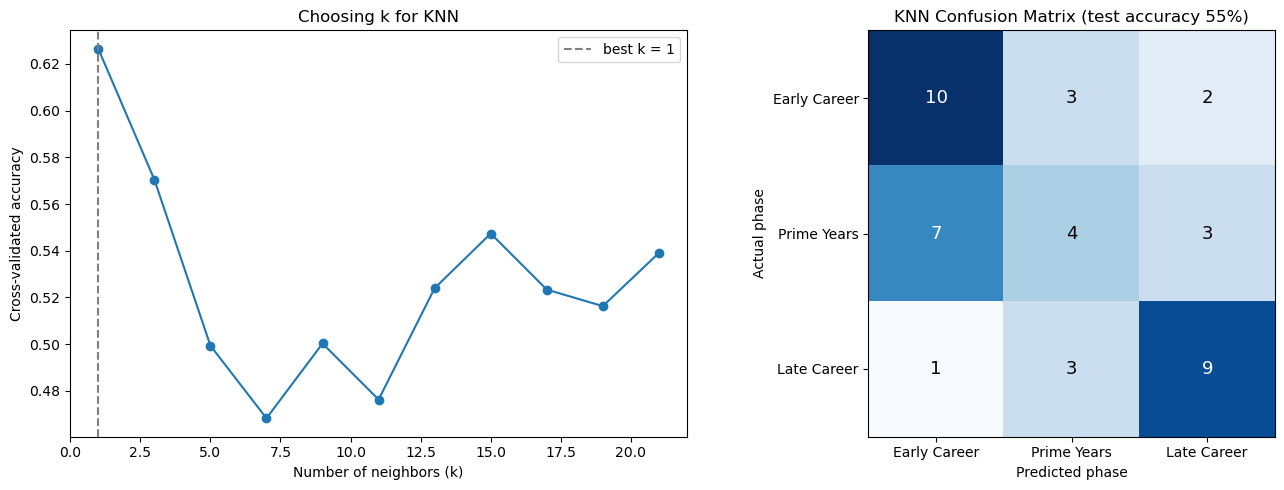

,k,CV_Accuracy
0,1,0.626
1,3,0.570
2,5,0.499
3,7,0.468
4,9,0.500
5,11,0.476
6,13,0.524
7,15,0.547
8,17,0.523
9,19,0.516


In [1]:
def insight6():
    import os
    os.environ["OMP_NUM_THREADS"] = "2"

    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    from ftfy import fix_text
    from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
    from sklearn.preprocessing import StandardScaler
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import Pipeline
    from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

    phase_order = ["Early Career", "Prime Years", "Late Career"]
    features = ["BPM", "PER", "TS%", "USG%", "WS/48", "AST%", "TRB%", "MP"]

    # career phase labels created by K-Means in Insight 3
    phases = pd.read_csv("insight3_career_phases.csv")
    phases = phases[phases["Type"] == "Regular"][["Player", "Season", "Phase"]]

    # advanced stats for the same player-seasons
    adv = pd.read_csv("clean_adv_box_scores.csv", low_memory=False)
    adv["Player"] = adv["Player"].apply(lambda x: fix_text(str(x)).strip())
    adv["Player"] = adv["Player"].str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("utf-8").str.strip()
    adv = adv[adv["Type"] == "Regular"]
    for col in features:
        adv[col] = pd.to_numeric(adv[col], errors="coerce")
    adv = adv.groupby(["Player", "Season"], as_index=False)[features].mean()

    # join labels to features (age is NOT used as a feature)
    df = phases.merge(adv, on=["Player", "Season"], how="inner").dropna(subset=features + ["Phase"])
    X = df[features]
    y = df["Phase"]

    # hold out 25% of seasons for testing, keeping the phase mix the same in both sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

    # scale features, then KNN; choose k with 5-fold cross-validation on the training set
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    k_values = list(range(1, 22, 2))
    cv_scores = []
    for k in k_values:
        model = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k))])
        cv_scores.append(cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy").mean())
    best_k = k_values[int(np.argmax(cv_scores))]

    # fit the final model and evaluate on the untouched test set
    model = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=best_k))])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)
    baseline = y_test.value_counts(normalize=True).max()

    print(f"Player-seasons used: {len(df)} (train {len(X_train)}, test {len(X_test)})")
    print(f"Best k (5-fold CV): {best_k}  |  CV accuracy: {max(cv_scores):.3f}")
    print(f"Test accuracy: {test_acc:.3f}  vs. baseline (always guess most common phase): {baseline:.3f}")
    print()
    print(classification_report(y_test, y_pred, labels=phase_order, zero_division=0))

    # plots: accuracy vs. k, and confusion matrix
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(k_values, cv_scores, marker="o")
    axes[0].axvline(best_k, color="gray", linestyle="--", label=f"best k = {best_k}")
    axes[0].set_xlabel("Number of neighbors (k)")
    axes[0].set_ylabel("Cross-validated accuracy")
    axes[0].set_title("Choosing k for KNN")
    axes[0].legend()

    cm = confusion_matrix(y_test, y_pred, labels=phase_order)
    axes[1].imshow(cm, cmap="Blues")
    axes[1].set_xticks(range(3))
    axes[1].set_xticklabels(phase_order)
    axes[1].set_yticks(range(3))
    axes[1].set_yticklabels(phase_order)
    axes[1].set_xlabel("Predicted phase")
    axes[1].set_ylabel("Actual phase")
    axes[1].set_title(f"KNN Confusion Matrix (test accuracy {test_acc:.0%})")
    for i in range(3):
        for j in range(3):
            axes[1].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)

    plt.tight_layout()
    plt.show()

    results = pd.DataFrame({"k": k_values, "CV_Accuracy": np.round(cv_scores, 3)})
    results.to_csv("insight6_knn_k_selection.csv", index=False)
    return results

############ Function Call ############
insight6()

## Data Visualizations

### Visualization 1 Explanation

This visualization highlights players’ career-high performances across multiple statistical categories in a heatmap format, with normalized values allowing each category to be compared on the same scale. This is especially important because it shows that dominance does not look the same for every player: some players stand out most as scorers, others as playmakers, rebounders, or defensive anchors. By displaying each player’s strongest categories side by side, the heatmap makes it much easier to see the different ways each player was dominant at their peak. This shows that Jordan had better "peak performances", however LeBron was not far behind.

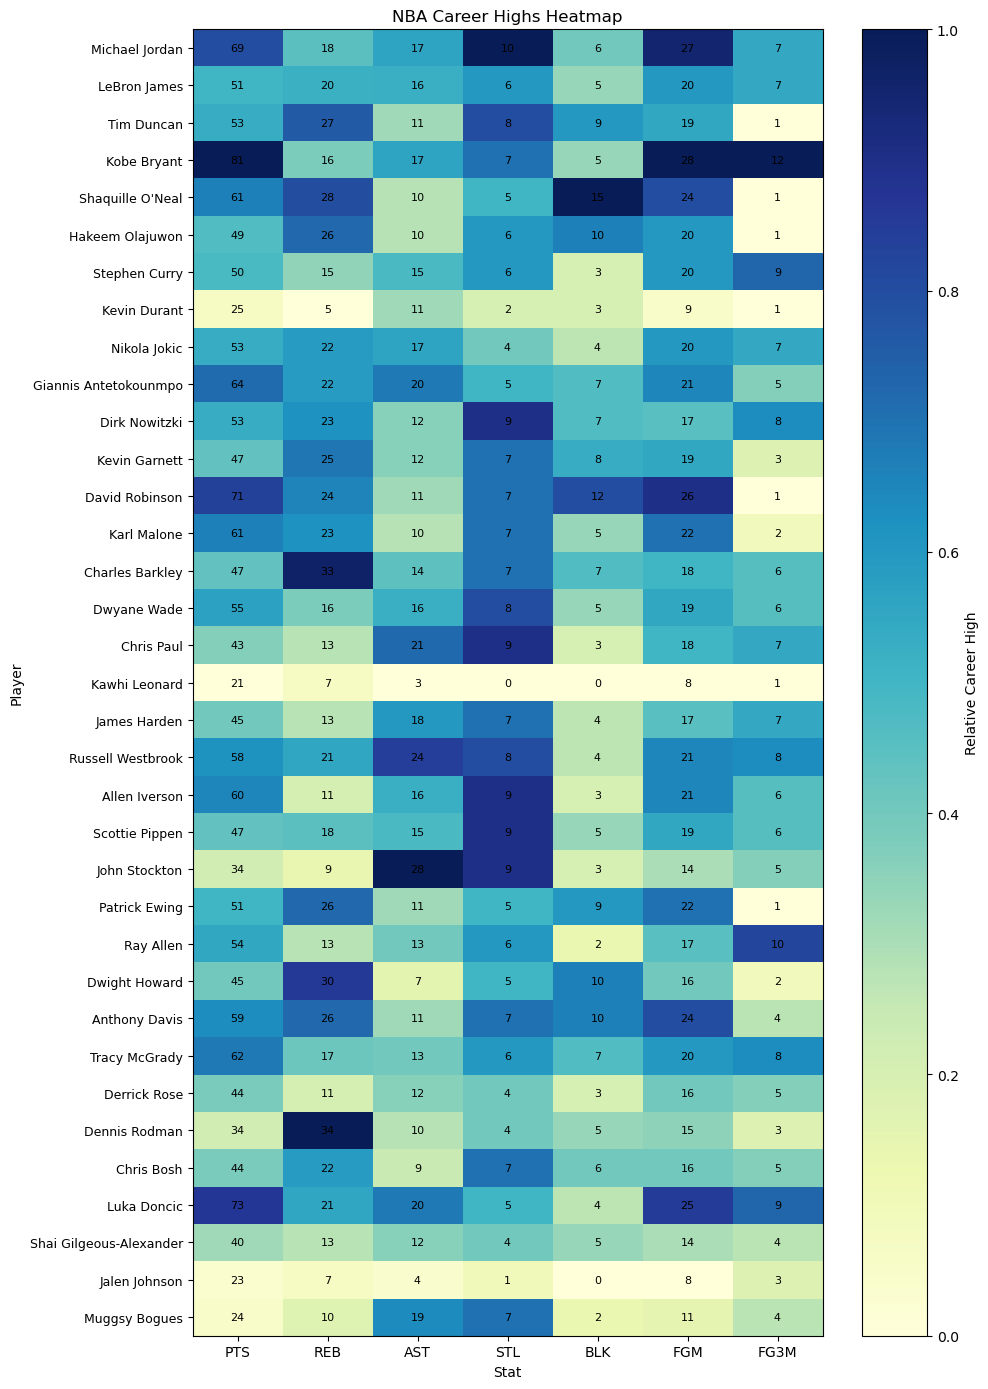

In [19]:
def visual1():
    #load data
    df = pd.read_csv("NBA_Career_Highs_1985_2025.csv")

    #set stats
    stats = ["PTS", "REB", "AST", "STL", "BLK", "FGM", "FG3M"]

    #keep needed columns
    plot_df = df[["Player"] + stats].copy()
    plot_df[stats] = plot_df[stats].apply(pd.to_numeric, errors="coerce")

    #normalize stats
    norm_df = plot_df.copy()
    for stat in stats:
        stat_min = norm_df[stat].min()
        stat_max = norm_df[stat].max()
        if stat_max != stat_min:
            norm_df[stat] = (norm_df[stat] - stat_min) / (stat_max - stat_min)
        else:
            norm_df[stat] = 0

    #align actual values
    actual_df = plot_df.set_index("Player").loc[norm_df["Player"]].reset_index()
    data = norm_df[stats].values

    #make plot
    fig, ax = plt.subplots(figsize=(10, max(8, len(norm_df) * 0.4)))
    im = ax.imshow(data, aspect="auto", cmap="YlGnBu")

    #format axes
    ax.set_xticks(np.arange(len(stats)))
    ax.set_xticklabels(stats, fontsize=10)
    ax.set_yticks(np.arange(len(norm_df)))
    ax.set_yticklabels(norm_df["Player"], fontsize=9)
    ax.set_title("NBA Career Highs Heatmap")
    ax.set_xlabel("Stat")
    ax.set_ylabel("Player")

    #label cells
    for i in range(len(actual_df)):
        for j, stat in enumerate(stats):
            val = actual_df.iloc[i][stat]
            ax.text(j, i, f"{int(val)}", ha="center", va="center", fontsize=8, color="black")

    #add colorbar
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("Relative Career High")

    plt.tight_layout()
    plt.show()

############ Function Call ############
visual1()

### Visualization 2 Explanation

This visualization compares players through major awards and honors, showing how dominance can take different forms across careers. Some players stand out more through scoring-driven awards like MVP and Finals MVP, while others show more two-way prowess through combinations of DPOY, All-NBA, and All-Defensive recognition. By displaying these achievements side by side, the visualization makes it much easier to see the different ways each player established dominance, and it suggests that Jordan had the strongest overall peak, though LeBron was not far behind.

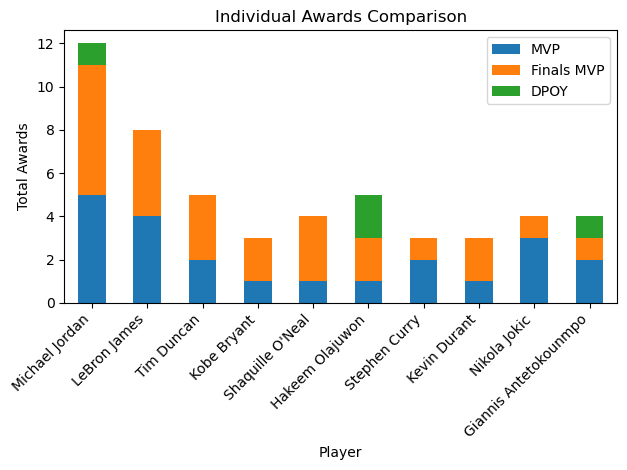

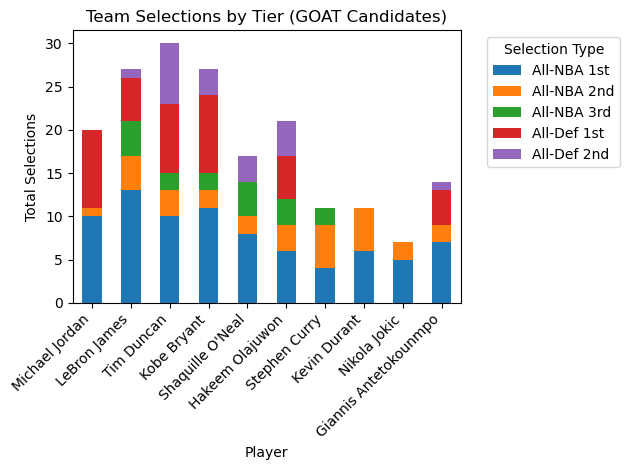

In [18]:
def visual2():
    #load data
    df = pd.read_csv("NBA_Awards_1985_2025.csv")

    #set players
    selected_players = ["Michael Jordan", "LeBron James", "Tim Duncan", "Kobe Bryant", "Shaquille O'Neal", "Hakeem Olajuwon", "Stephen Curry", "Kevin Durant", "Nikola Jokic", "Giannis Antetokounmpo"]

    #clean columns
    df["Player"] = df["Player"].astype(str).str.strip()
    df["Season"] = df["Season"].astype(str).str.strip()
    df = df.fillna("No")

    def count_award_winners(data, award_col):
        #count winner rows by player
        award_df = data[["Season", "Player", award_col]].copy()
        award_df[award_col] = award_df[award_col].astype(str).str.strip().str.lower()
        award_df = award_df[award_df[award_col] == "winner"].copy()
        award_df = award_df.drop_duplicates(subset=["Season", "Player"])
        return award_df["Player"].value_counts()

    def count_team_selection(series, label):
        #count team selections by label
        return series.astype(str).str.contains(label, case=False, na=False).sum()

    #count individual awards
    mvp_counts = count_award_winners(df, "MVP")
    dpoy_counts = count_award_winners(df, "DPOY")
    finals_mvp_counts = count_award_winners(df, "Finals MVP")

    #build individual awards table
    individual_data = []
    for player in selected_players:
        individual_data.append([player, int(mvp_counts.get(player, 0)), int(finals_mvp_counts.get(player, 0)), int(dpoy_counts.get(player, 0))])

    indiv_df = pd.DataFrame(individual_data, columns=["Player", "MVP", "Finals MVP", "DPOY"]).set_index("Player")

    #plot individual awards
    indiv_df.plot(kind="bar", stacked=True)
    plt.title("Individual Awards Comparison")
    plt.xlabel("Player")
    plt.ylabel("Total Awards")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    #keep one row per player-season
    player_df_all = df[df["Player"].isin(selected_players)].copy()
    player_df_all = player_df_all.drop_duplicates(subset=["Player", "Season"])

    #build team selections table
    team_data = []
    for player in selected_players:
        player_df = player_df_all[player_df_all["Player"] == player]
        nba_1 = count_team_selection(player_df["All-NBA"], "1st")
        nba_2 = count_team_selection(player_df["All-NBA"], "2nd")
        nba_3 = count_team_selection(player_df["All-NBA"], "3rd")
        def_1 = count_team_selection(player_df["All-Defensive"], "1st")
        def_2 = count_team_selection(player_df["All-Defensive"], "2nd")
        team_data.append([player, nba_1, nba_2, nba_3, def_1, def_2])

    team_df = pd.DataFrame(team_data, columns=["Player", "All-NBA 1st", "All-NBA 2nd", "All-NBA 3rd", "All-Def 1st", "All-Def 2nd"]).set_index("Player")

    #plot team selections
    team_df.plot(kind="bar", stacked=True)
    plt.title("Team Selections by Tier (GOAT Candidates)")
    plt.xlabel("Player")
    plt.ylabel("Total Selections")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Selection Type", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

############ Function Call ############
visual2()

### Visualization 3 Explanation

This visualization helps show Insight 4, where the actual award winner is compared against the most statistically dominant player. This is especially important because it reveals that awards do not always go to the most statistically dominant player, and LeBron is one of the clearest examples of that. In some seasons, he appears to have been snubbed in awards like Finals MVP simply because his team did not win the series, and in the MVP race, voter fatigue likely played a role as well, since once a player has already won multiple times, voters often become less willing to keep rewarding him.

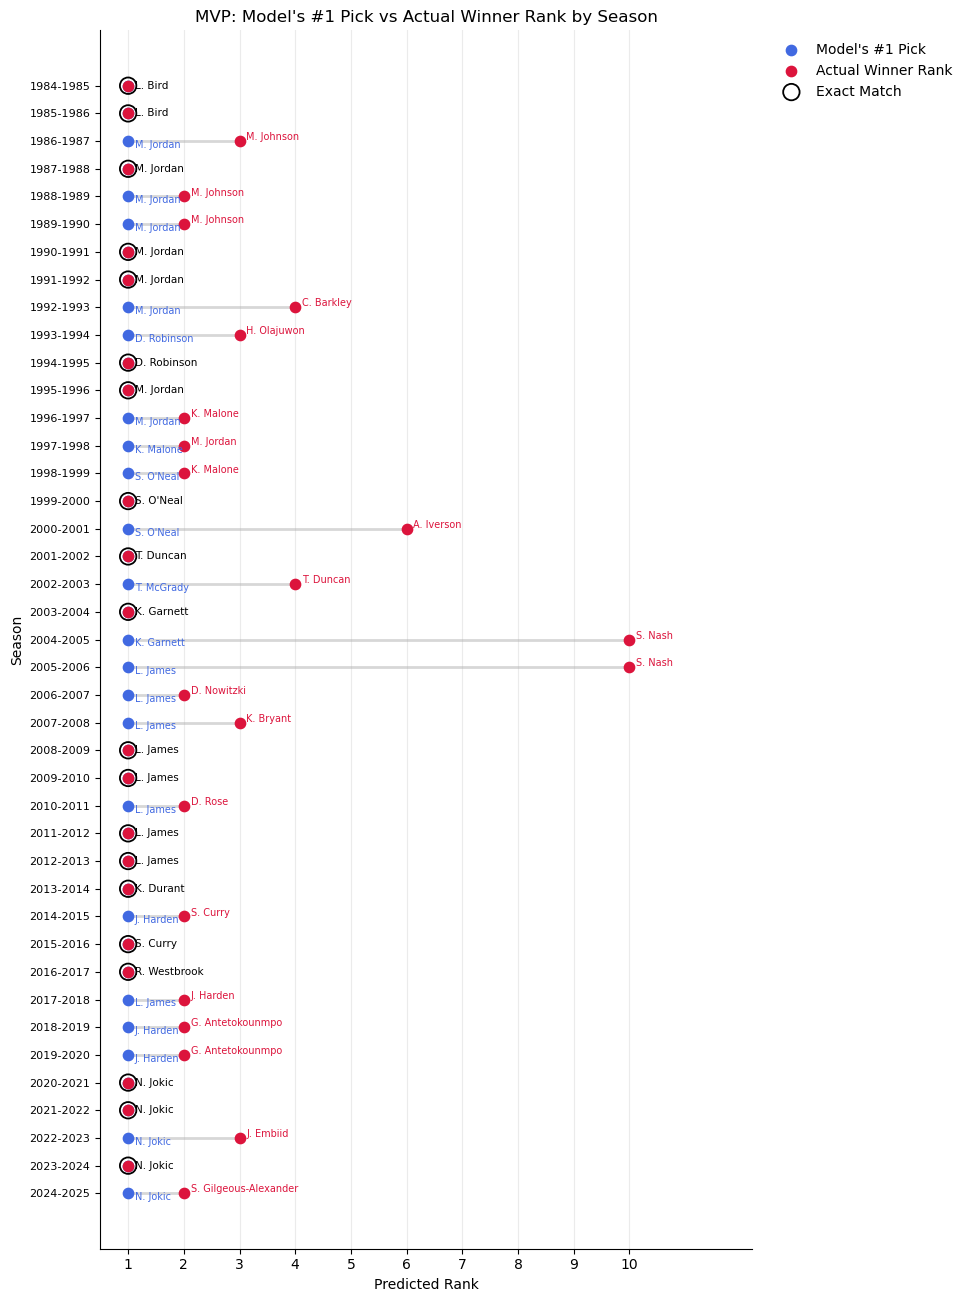

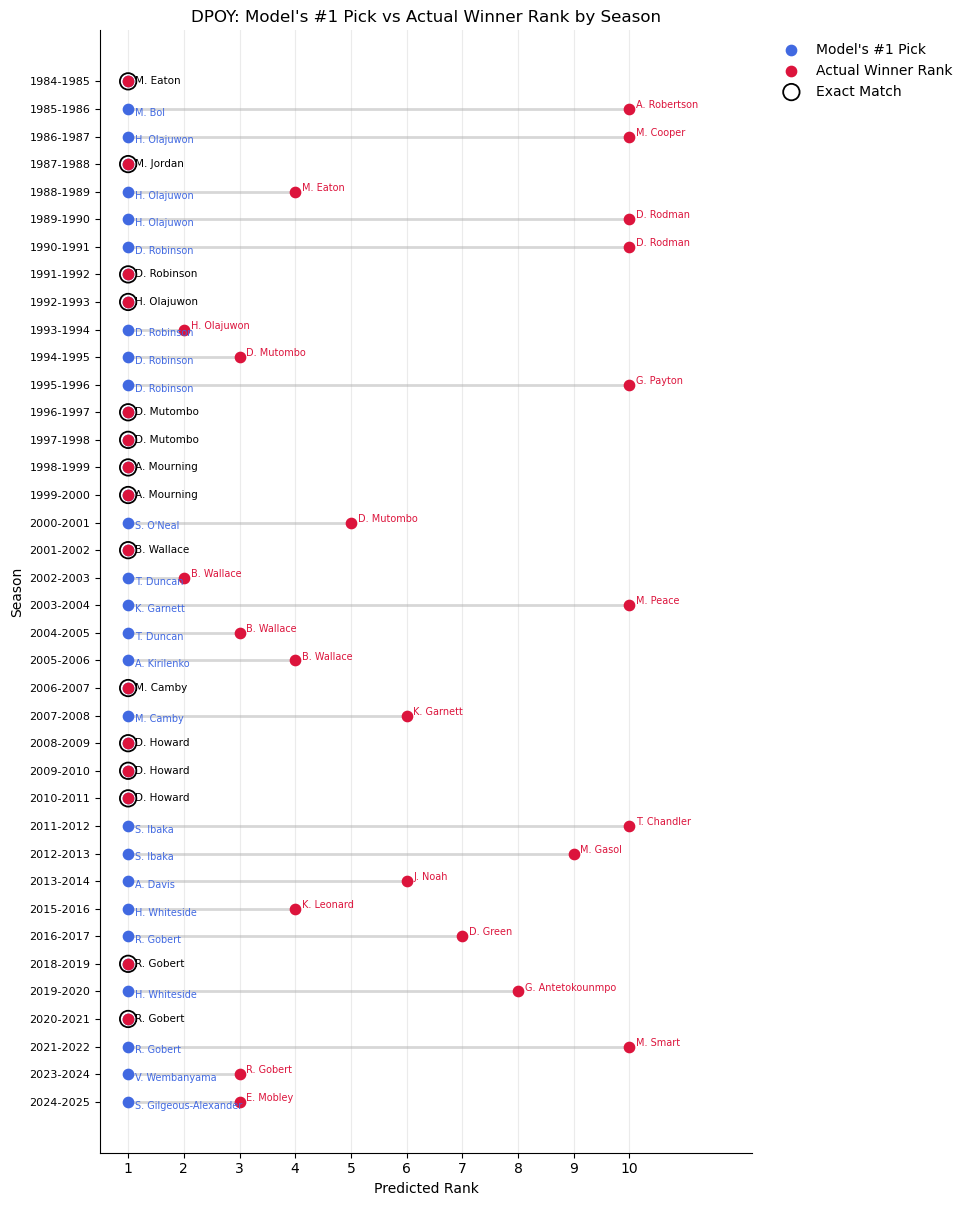

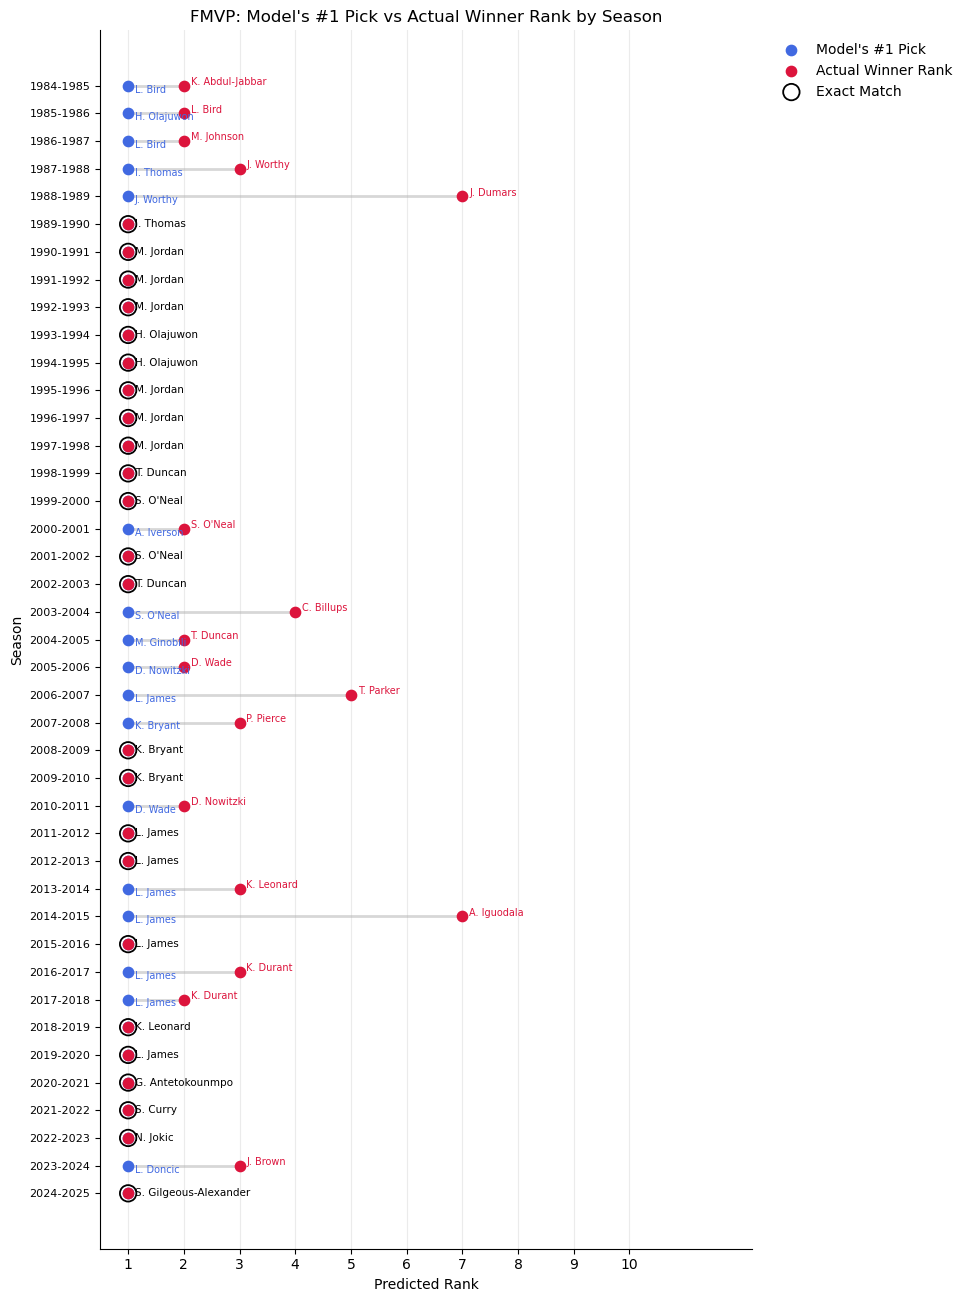

In [17]:
def visual3():
    #load and sort data
    df = pd.read_csv("award_rank_season_results.csv")
    df["Season_Start"] = df["Season"].apply(lambda s: int(str(s).split("-")[0]))
    df = df.sort_values(["Award", "Season_Start"]).reset_index(drop=True)

    #set rank cap
    valid = df.dropna(subset=["Actual_Winner_Rank"]).copy()
    for col in ["Actual_Winner_Rank", "Predicted_Rank"]:
        valid[col] = pd.to_numeric(valid[col], errors="coerce")
    shown_max = min(int(max(valid["Actual_Winner_Rank"].max(), valid["Predicted_Rank"].max())), 10)

    #shorten names
    short = lambda n: f"{n.split()[0][0]}. {n.split()[-1]}" if len(n.split()) > 1 else n.strip()

    for award in ["MVP", "DPOY", "FMVP"]:
        #filter one award
        adf = df[(df["Award"] == award)].dropna(subset=["Actual_Winner_Rank"]).copy().reset_index(drop=True)
        if adf.empty:
            continue

        #prep plot values
        adf[["Actual_Winner_Rank", "Predicted_Rank"]] = adf[["Actual_Winner_Rank", "Predicted_Rank"]].astype(int)
        y = np.arange(len(adf))
        px = adf["Predicted_Rank"].clip(upper=shown_max)
        ax_val = adf["Actual_Winner_Rank"].clip(upper=shown_max)

        #create plot
        fig, ax = plt.subplots(figsize=(12, max(8, len(adf) * 0.32)))

        #connect predicted and actual ranks
        for i, row in adf.iterrows():
            ax.plot([px.iloc[i], ax_val.iloc[i]], [y[i], y[i]], color="lightgray", lw=2, alpha=0.9, zorder=1)

        #plot predicted and actual points
        ax.scatter(px, y, s=55, color="royalblue", label="Model's #1 Pick", zorder=3)
        ax.scatter(ax_val, y, s=55, color="crimson", label="Actual Winner Rank", zorder=3)

        #highlight exact matches
        exact = adf["Actual_Winner_Rank"] == adf["Predicted_Rank"]
        if exact.any():
            ax.scatter(ax_val[exact], y[exact], s=140, facecolors="none", edgecolors="black", lw=1.3, label="Exact Match", zorder=4)

        #label players
        for i, row in adf.iterrows():
            pn, an = short(str(row["Predicted_Player"])), short(str(row["Actual_Winner"]))
            pr, ar = min(int(row["Predicted_Rank"]), shown_max), min(int(row["Actual_Winner_Rank"]), shown_max)
            if pn == an and pr == ar:
                ax.text(ar + 0.12, y[i], an, fontsize=7.5, va="center", ha="left", color="black", clip_on=False)
            else:
                ax.text(pr + 0.12, y[i] + 0.14, pn, fontsize=7, va="center", ha="left", color="royalblue", clip_on=False)
                ax.text(ar + 0.12, y[i] - 0.14, an, fontsize=7, va="center", ha="left", color="crimson", clip_on=False)

        #format plot
        ax.set_yticks(y)
        ax.set_yticklabels(adf["Season"], fontsize=8)
        ax.invert_yaxis()
        ax.set_xlim(0.5, shown_max + 2.2)
        ax.set_xticks(range(1, shown_max + 1))
        ax.set_xlabel("Predicted Rank")
        ax.set_ylabel("Season")
        ax.set_title(f"{award}: Model's #1 Pick vs Actual Winner Rank by Season")
        ax.grid(True, axis="x", alpha=0.25)
        ax.grid(False, axis="y")
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)
        ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False)
        plt.tight_layout(rect=[0, 0, 0.82, 1])
        plt.show()

############ Function Call ############
visual3()

### Visualization 4 Explanation

This visualization helps bring Insight 3 to life by showing how each player’s BPM changed across different stages of their career. This is especially important because it makes it much easier to see which players had the highest peaks, which players stayed dominant for the longest, and how their impact changed throughout their career. By showing both regular season and playoff BPM with these career phases, the visualization gives a much clearer picture of player dominance over time, and shows Lebron's consistency and Jordan's peaks.

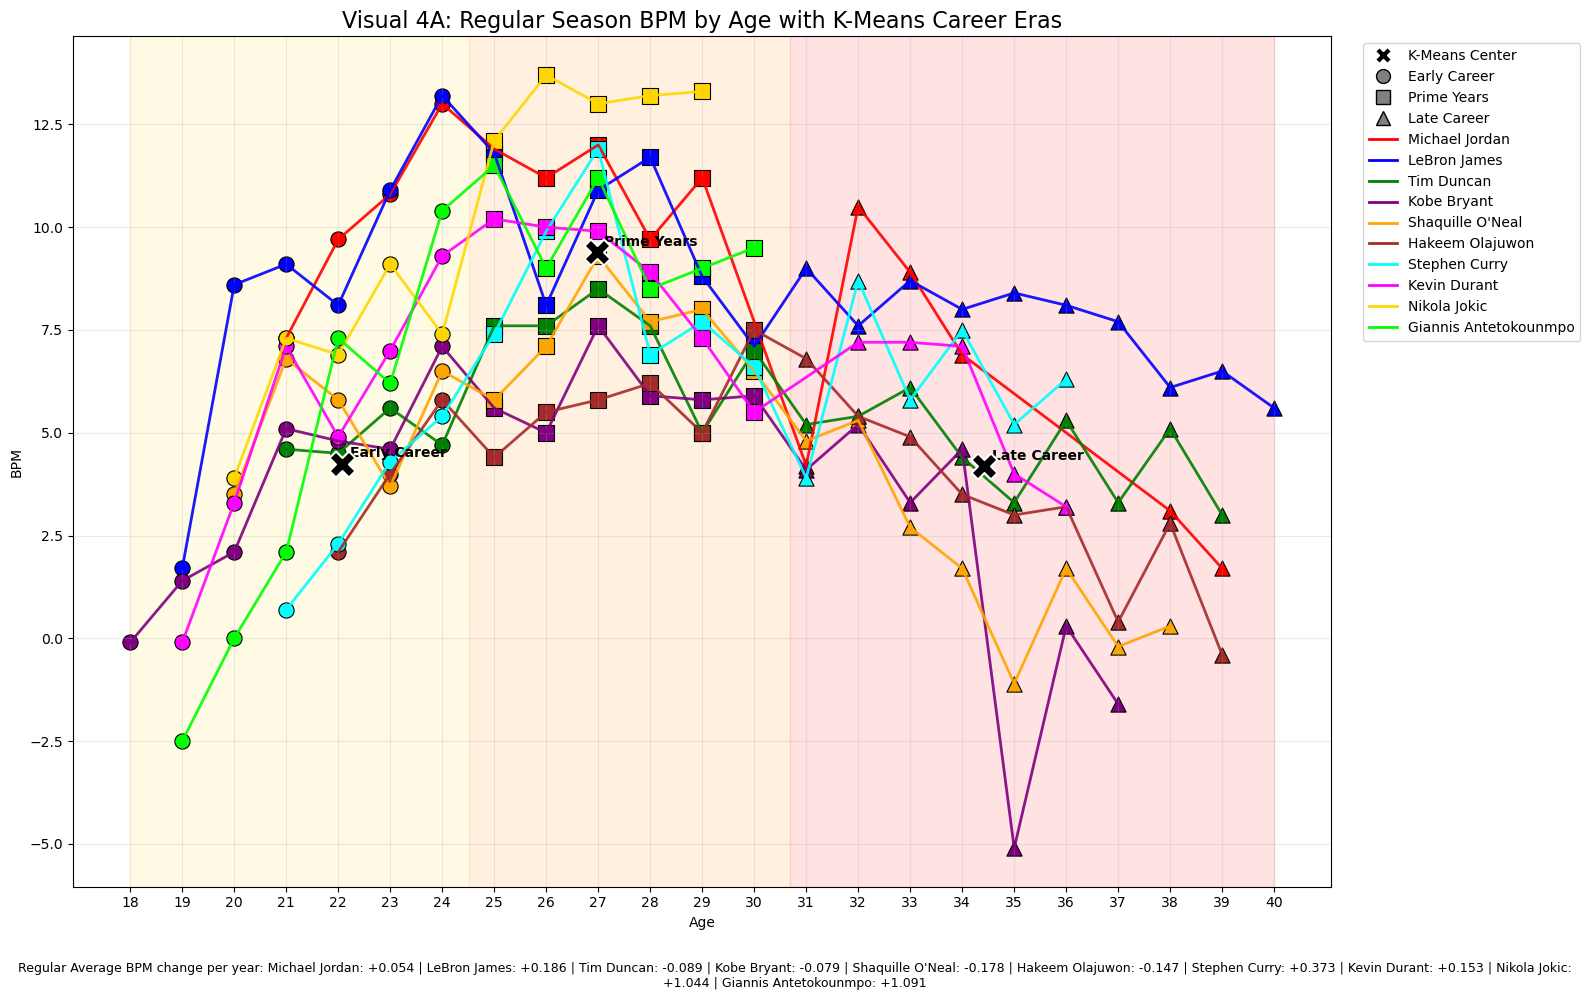

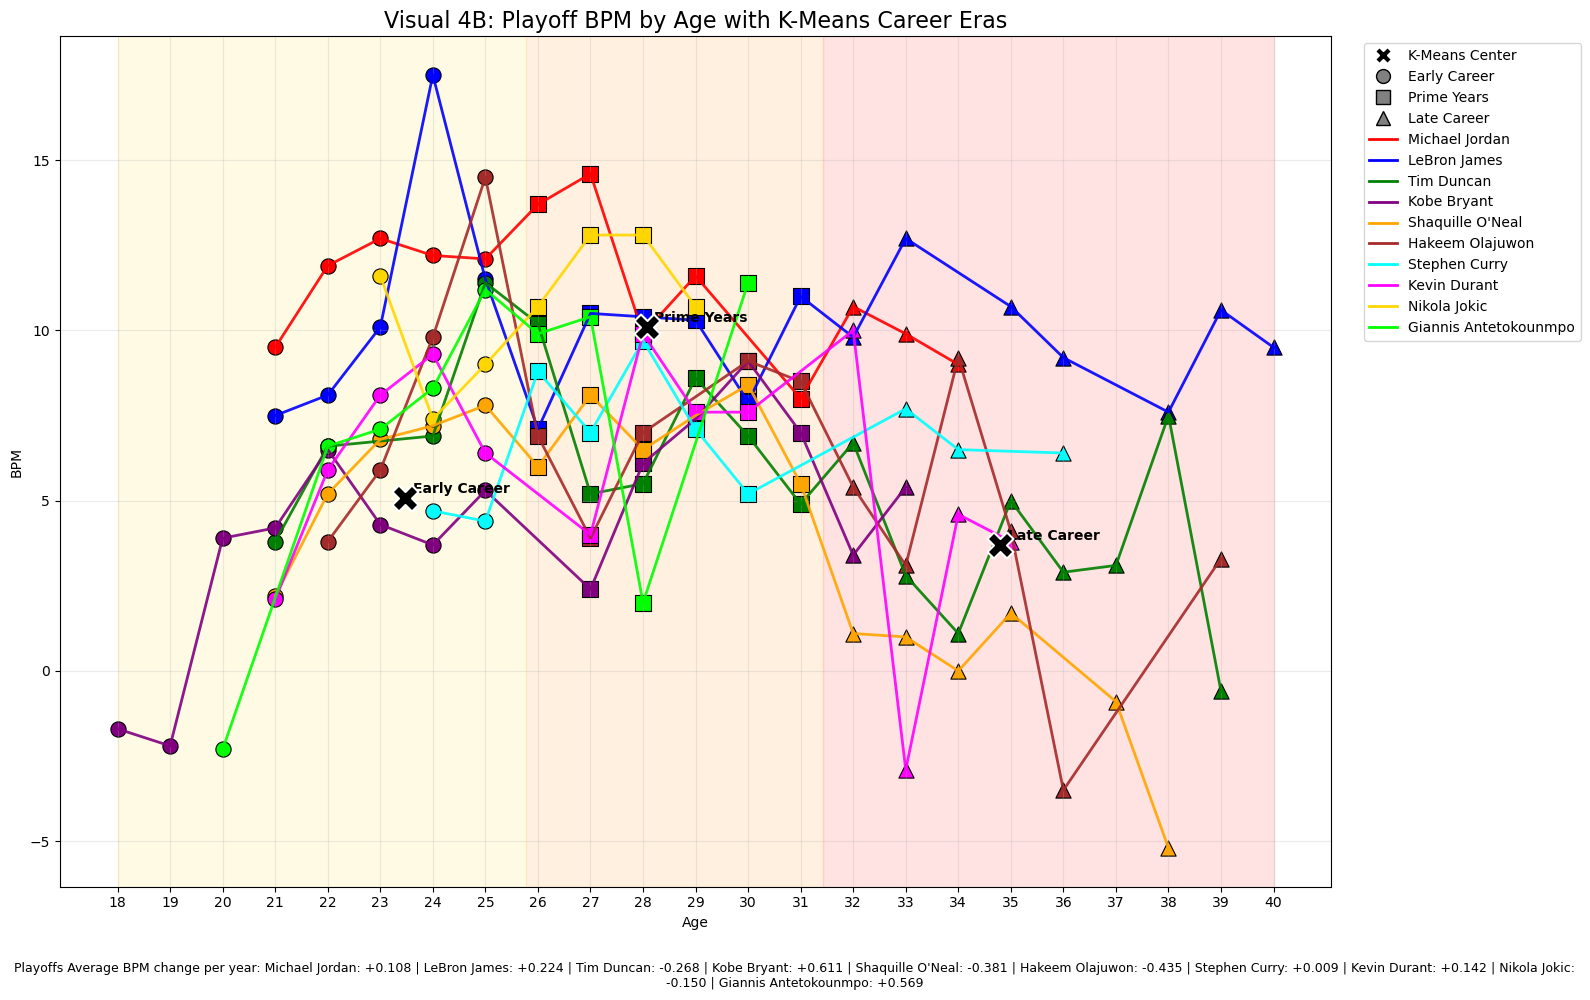

In [16]:
def visual4():
    import os
    #fixes warning when running code
    os.environ["OMP_NUM_THREADS"] = "1"

    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    from ftfy import fix_text
    from sklearn.preprocessing import StandardScaler
    from sklearn.cluster import KMeans

    #define players
    selected_players = ["Michael Jordan", "LeBron James", "Tim Duncan", "Kobe Bryant", "Shaquille O'Neal", "Hakeem Olajuwon", "Stephen Curry", "Kevin Durant", "Nikola Jokic", "Giannis Antetokounmpo"]

    #define player colors for line plots
    player_colors = {"Michael Jordan": "red", "LeBron James": "blue", "Tim Duncan": "green", "Kobe Bryant": "purple", "Shaquille O'Neal": "orange", "Hakeem Olajuwon": "brown", "Stephen Curry": "cyan", "Kevin Durant": "magenta", "Nikola Jokic": "gold", "Giannis Antetokounmpo": "lime"}

    #define markers and background colors for each career phase
    phase_markers = {"Early Career": "o", "Prime Years": "s", "Late Career": "^"}
    phase_colors = {"Early Career": "#fff3b0", "Prime Years": "#ffd6a5", "Late Career": "#ffadad"}

    #load and clean the advanced stats file
    df = pd.read_csv("clean_adv_box_scores.csv")
    df["Player"] = df["Player"].apply(lambda x: fix_text(str(x)).strip())
    df["Player"] = df["Player"].str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("utf-8").str.strip()
    df["Player"] = df["Player"].replace({"Nikola Jokić": "Nikola Jokic"})

    #keep only the columns needed for the visual
    df = df[["Player", "Season", "Age", "BPM", "Type"]]
    df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
    df["BPM"] = pd.to_numeric(df["BPM"], errors="coerce")
    df["Type"] = df["Type"].astype(str).str.strip()

    #filter to selected players and valid season types
    df = df[df["Player"].isin(selected_players)]
    df = df[df["Type"].isin(["Regular", "Playoffs"])]
    df = df.dropna(subset=["Player", "Season", "Age", "BPM", "Type"])

    #average BPM for each player-season-age-type combination
    df = df.groupby(["Player", "Season", "Age", "Type"], as_index=False, sort=False)["BPM"].mean()

    def plot_one(data, season_type, save_name, title_text):
        #filter to one season type
        temp = data[data["Type"] == season_type].copy()
        if len(temp) == 0:
            return

        #run k-means on age and BPM to estimate career phases
        scaler = StandardScaler()
        X = scaler.fit_transform(temp[["Age", "BPM"]])
        kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
        kmeans.fit(X)

        #convert cluster centers back to the original scale and sort them by age
        centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=["Age", "BPM"])
        centers = centers.sort_values("Age").reset_index(drop=True)
        centers["Phase"] = ["Early Career", "Prime Years", "Late Career"]

        #use midpoints between centers as career phase boundaries
        age_bounds = sorted(centers["Age"])
        b1 = (age_bounds[0] + age_bounds[1]) / 2
        b2 = (age_bounds[1] + age_bounds[2]) / 2

        #assign phases by age so each player progresses forward logically
        temp["Phase"] = np.where(temp["Age"] < b1, "Early Career", np.where(temp["Age"] < b2, "Prime Years", "Late Career"))

        #preserve the original player order
        temp["Player"] = pd.Categorical(temp["Player"], categories=selected_players, ordered=True)
        temp = temp.sort_values(["Player", "Age", "Season"]).reset_index(drop=True)
        temp["Player"] = temp["Player"].astype(str)

        #calculate each player's average BPM change per year
        bpm_change = {}
        for player in selected_players:
            p = temp[temp["Player"] == player].sort_values(["Age", "Season"]).copy()
            if len(p) == 0:
                continue
            age_diff = p["Age"].diff()
            bpm_diff = p["BPM"].diff()
            yearly_change = (bpm_diff / age_diff).replace([np.inf, -np.inf], np.nan).dropna()
            bpm_change[player] = round(yearly_change.mean(), 3) if len(yearly_change) > 0 else None

        #create the plot
        fig, ax = plt.subplots(figsize=(16, 10))

        #shade the background by career phase
        ax.axvspan(18, b1, color=phase_colors["Early Career"], alpha=0.35)
        ax.axvspan(b1, b2, color=phase_colors["Prime Years"], alpha=0.35)
        ax.axvspan(b2, 40, color=phase_colors["Late Career"], alpha=0.35)

        #plot each player's BPM trend and phase markers
        for player in selected_players:
            p = temp[temp["Player"] == player].sort_values(["Age", "Season"]).copy()
            if len(p) == 0:
                continue
            ax.plot(p["Age"], p["BPM"], color=player_colors[player], linewidth=2, alpha=0.9, label=player)
            for phase in ["Early Career", "Prime Years", "Late Career"]:
                phase_df = p[p["Phase"] == phase]
                ax.scatter(phase_df["Age"], phase_df["BPM"], marker=phase_markers[phase], s=120, color=player_colors[player], edgecolor="black", linewidth=0.8)

        #plot the k-means centers
        for _, row in centers.iterrows():
            ax.scatter(row["Age"], row["BPM"], marker="X", s=350, color="black", edgecolor="white", linewidth=1.5, zorder=5)
            ax.text(row["Age"] + 0.15, row["BPM"] + 0.15, row["Phase"], fontsize=10, weight="bold")

        #build legend entries
        player_handles = [plt.Line2D([0], [0], color=player_colors[p], linewidth=2, label=p) for p in selected_players]
        phase_handles = [plt.Line2D([0], [0], marker=phase_markers[ph], linestyle="None", markerfacecolor="gray", markeredgecolor="black", markersize=10, label=ph) for ph in ["Early Career", "Prime Years", "Late Career"]]
        mean_handle = plt.Line2D([0], [0], marker="X", linestyle="None", markerfacecolor="black", markeredgecolor="white", markersize=12, label="K-Means Center")

        #format and display the final visual
        summary_text = season_type + " Average BPM change per year: " + " | ".join([f"{p}: {bpm_change[p]:+.3f}" for p in selected_players if p in bpm_change and bpm_change[p] is not None])
        ax.set_title(title_text, fontsize=16)
        ax.set_xlabel("Age")
        ax.set_ylabel("BPM")
        ax.set_xticks(range(18, 41))
        ax.grid(alpha=0.25)
        ax.legend(handles=[mean_handle] + phase_handles + player_handles, bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.figtext(0.5, 0.01, summary_text, ha="center", fontsize=9, wrap=True)
        plt.tight_layout(rect=[0, 0.05, 1, 1])
        plt.savefig(save_name, dpi=300, bbox_inches="tight")
        plt.show()

    #generate both visuals
    plot_one(df, "Regular", "visual4_regular_bpm_kmeans.png", "Visual 4A: Regular Season BPM by Age with K-Means Career Eras")
    plot_one(df, "Playoffs", "visual4_playoffs_bpm_kmeans.png", "Visual 4B: Playoff BPM by Age with K-Means Career Eras")


############ Function Call ############
visual4()

# SQL Analysis (SQLite)

All five cleaned datasets are loaded into a SQLite database (`nba.db`), and several of the project's questions are answered directly in SQL using joins, conditional aggregation (`CASE WHEN`), and window functions (`ROW_NUMBER()`). Run the data collection functions above first so the CSV files exist.

In [2]:
import sqlite3
import re
import pandas as pd
from ftfy import fix_text

def sql_name(col):
    """Make column names SQL-friendly: 'TS%' -> TS_pct, 'WS/48' -> WS_per_48, '3PA' -> FG3A, 'Finals MVP' -> Finals_MVP"""
    col = re.sub(r"^3P", "FG3", str(col).strip())
    col = re.sub(r"^2P", "FG2", col)
    col = col.replace("%", "_pct").replace("/", "_per_")
    col = re.sub(r"[^0-9a-zA-Z_]", "_", col)
    return re.sub(r"_+", "_", col).strip("_")

tables = {
    "box_scores":   "clean_downloaded_box_scores.csv",
    "advanced":     "clean_adv_box_scores.csv",
    "awards":       "NBA_Awards_1985_2025.csv",
    "career_highs": "NBA_Career_Highs_1985_2025.csv",
    "finals_odds":  "nba_finals_series_odds_1985_2025.csv",
}

conn = sqlite3.connect("nba.db")
for table, file in tables.items():
    df = pd.read_csv(file, encoding="utf-8", encoding_errors="replace", low_memory=False)
    df.columns = [sql_name(c) for c in df.columns]
    df = df.loc[:, ~df.columns.duplicated()]
    if "Player" in df.columns:   # same name cleaning as the pandas analysis (e.g. Jokić -> Jokic)
        df["Player"] = df["Player"].apply(lambda x: fix_text(str(x)).strip())
        df["Player"] = df["Player"].str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("utf-8").str.strip()
    if "Season" in df.columns:   # '1995-1996' -> 1995, for decade/era queries
        df["Season_Start"] = pd.to_numeric(df["Season"].astype(str).str[:4], errors="coerce")
    df.to_sql(table, conn, if_exists="replace", index=False)

# the 10 players this project focuses on
pd.DataFrame({"Player": ["Michael Jordan", "LeBron James", "Tim Duncan", "Kobe Bryant", "Shaquille O'Neal",
                         "Hakeem Olajuwon", "Stephen Curry", "Kevin Durant", "Nikola Jokic", "Giannis Antetokounmpo"]}
            ).to_sql("focus_players", conn, if_exists="replace", index=False)

def sql(query):
    return pd.read_sql_query(query, conn)

# summary of the database: one row per table
pd.DataFrame([(t, sql(f"SELECT COUNT(*) AS n FROM {t}").n[0], len(sql(f"SELECT * FROM {t} LIMIT 1").columns))
              for t in sql("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name").name],
             columns=["table", "rows", "columns"])

,table,rows,columns
0,advanced,26533,32
1,awards,2529,13
2,box_scores,26533,34
3,career_highs,35,14
4,finals_odds,41,6
5,focus_players,10,1


In [3]:
# 1. Regular season vs. playoff efficiency: minutes-weighted TS% for each player
sql("""
SELECT a.Player,
       ROUND(SUM(CASE WHEN a.Type = 'Regular'  THEN a.TS_pct * a.MP END) / SUM(CASE WHEN a.Type = 'Regular'  THEN a.MP END), 3) AS regular_ts,
       ROUND(SUM(CASE WHEN a.Type = 'Playoffs' THEN a.TS_pct * a.MP END) / SUM(CASE WHEN a.Type = 'Playoffs' THEN a.MP END), 3) AS playoff_ts,
       ROUND(SUM(CASE WHEN a.Type = 'Playoffs' THEN a.TS_pct * a.MP END) / SUM(CASE WHEN a.Type = 'Playoffs' THEN a.MP END)
           - SUM(CASE WHEN a.Type = 'Regular'  THEN a.TS_pct * a.MP END) / SUM(CASE WHEN a.Type = 'Regular'  THEN a.MP END), 3) AS playoff_change
FROM advanced a
JOIN focus_players f ON f.Player = a.Player
GROUP BY a.Player
ORDER BY playoff_change DESC
""")

,Player,regular_ts,playoff_ts,playoff_change
0,Hakeem Olajuwon,0.552,0.569,0.018
1,Michael Jordan,0.568,0.568,0.000
2,Tim Duncan,0.550,0.548,-0.002
3,LeBron James,0.590,0.585,-0.005
4,Kobe Bryant,0.550,0.540,-0.010
5,Stephen Curry,0.622,0.607,-0.015
6,Kevin Durant,0.620,0.600,-0.020
7,Shaquille O'Neal,0.587,0.565,-0.022
8,Nikola Jokic,0.636,0.611,-0.024
9,Giannis Antetokounmpo,0.603,0.577,-0.026


In [4]:
# 2. How the league changed by decade: 3-point attempt rate, scoring, and true shooting
sql("""
SELECT b.decade, b.three_point_attempt_rate, b.avg_pts_per_player_game, a.league_ts
FROM (SELECT (Season_Start / 10) * 10 AS decade,
             ROUND(SUM(FG3A * G) / SUM(FGA * G), 3) AS three_point_attempt_rate,
             ROUND(SUM(PTS * G) / SUM(G), 2)        AS avg_pts_per_player_game
      FROM box_scores WHERE Type = 'Regular' GROUP BY decade) b
JOIN (SELECT (Season_Start / 10) * 10 AS decade,
             ROUND(SUM(TS_pct * MP) / SUM(MP), 3)   AS league_ts
      FROM advanced WHERE Type = 'Regular' AND MP > 0 GROUP BY decade) a
  ON a.decade = b.decade
ORDER BY b.decade
""")

,decade,three_point_attempt_rate,avg_pts_per_player_game,league_ts
0,1980,0.056,10.68,0.537
1,1990,0.147,9.89,0.530
2,2000,0.200,9.63,0.529
3,2010,0.291,9.82,0.544
4,2020,0.399,10.63,0.575


In [5]:
# 3. Each player's peak regular season by BPM (window function)
sql("""
SELECT Player, Season, Age, ROUND(BPM, 1) AS BPM, ROUND(PER, 1) AS PER, ROUND(WS, 1) AS WS
FROM (SELECT a.Player, a.Season, a.Age, a.BPM, a.PER, a.WS,
             ROW_NUMBER() OVER (PARTITION BY a.Player ORDER BY a.BPM DESC) AS rn
      FROM advanced a
      JOIN focus_players f ON f.Player = a.Player
      WHERE a.Type = 'Regular')
WHERE rn = 1
ORDER BY BPM DESC
""")

,Player,Season,Age,BPM,PER,WS
0,Nikola Jokic,2021-2022,26.0,13.7,32.8,15.2
1,LeBron James,2008-2009,24.0,13.2,31.7,20.3
2,Michael Jordan,1987-1988,24.0,13.0,31.7,21.2
3,Stephen Curry,2015-2016,27.0,11.9,31.5,17.9
4,Giannis Antetokounmpo,2019-2020,25.0,11.5,31.9,11.1
5,Kevin Durant,2013-2014,25.0,10.2,29.8,19.2
6,Shaquille O'Neal,1999-2000,27.0,9.3,30.6,18.6
7,Tim Duncan,2003-2004,27.0,8.5,27.1,13.1
8,Kobe Bryant,2005-2006,27.0,7.6,28.0,15.3
9,Hakeem Olajuwon,1992-1993,30.0,7.5,27.3,15.8


In [6]:
# 4. Award resumes
sql("""
SELECT aw.Player,
       SUM(aw.MVP = 'Winner')        AS mvp,
       SUM(aw.DPOY = 'Winner')       AS dpoy,
       SUM(aw.Finals_MVP = 'Winner') AS finals_mvp,
       SUM(aw.All_NBA = '1st Team')  AS all_nba_1st,
       SUM(aw.All_NBA <> 'No')       AS all_nba_total,
       SUM(aw.All_Defensive <> 'No') AS all_defensive
FROM awards aw
JOIN focus_players f ON f.Player = aw.Player
GROUP BY aw.Player
ORDER BY mvp DESC, finals_mvp DESC, all_nba_total DESC
""")

,Player,mvp,dpoy,finals_mvp,all_nba_1st,all_nba_total,all_defensive
0,Michael Jordan,5,1,6,10,11,9
1,LeBron James,4,0,4,13,21,6
2,Nikola Jokic,3,0,1,5,7,0
3,Tim Duncan,2,0,3,10,15,15
4,Stephen Curry,2,0,1,4,11,0
5,Giannis Antetokounmpo,2,1,1,7,9,5
6,Shaquille O'Neal,1,0,3,8,14,3
7,Kobe Bryant,1,0,2,11,15,12
8,Hakeem Olajuwon,1,2,2,6,12,9
9,Kevin Durant,1,0,2,6,11,0


In [7]:
# 5. Most efficient high-volume scoring seasons since 1985 (joins per-game and advanced stats)
sql("""
SELECT b.Player, b.Season, b.PTS, a.TS_pct, a.USG_pct, ROUND(a.BPM, 1) AS BPM
FROM box_scores b
JOIN advanced a ON a.Player = b.Player AND a.Season = b.Season AND a.Type = b.Type
WHERE b.Type = 'Regular' AND b.PTS >= 25 AND b.G >= 50
ORDER BY a.TS_pct DESC
LIMIT 15
""")

,Player,Season,PTS,TS_pct,USG_pct,BPM
0,Stephen Curry,2017-2018,26.4,0.675,31.0,7.7
1,Stephen Curry,2015-2016,30.1,0.669,32.6,11.9
2,Charles Barkley,1987-1988,28.3,0.665,26.7,7.4
3,Nikola Jokic,2024-2025,29.6,0.663,29.5,13.3
4,Charles Barkley,1989-1990,25.2,0.661,24.0,8.2
5,Nikola Jokic,2021-2022,27.1,0.661,31.9,13.7
6,Amar'e Stoudemire,2007-2008,25.2,0.656,28.2,4.8
7,Stephen Curry,2022-2023,29.4,0.656,31.0,7.5
8,Kevin McHale,1986-1987,26.1,0.655,24.1,5.1
9,Stephen Curry,2020-2021,32.0,0.655,34.8,8.7


In [8]:
# 6. Biggest Finals upsets: the series winner was the betting underdog (positive odds)
sql("""
SELECT Year, Winning_Team,
       CASE WHEN Winning_Team = Home_Court_Team THEN Away_Court_Team ELSE Home_Court_Team END AS defeated,
       CASE WHEN Winning_Team = Home_Court_Team THEN Home_Court_Team_Odds ELSE Away_Court_Team_Odds END AS winner_odds
FROM finals_odds
WHERE CASE WHEN Winning_Team = Home_Court_Team THEN Home_Court_Team_Odds ELSE Away_Court_Team_Odds END > 0
ORDER BY winner_odds DESC
""")

,Year,Winning_Team,defeated,winner_odds
0,2004,Detroit Pistons,Los Angeles Lakers,500.0
1,2019,Toronto Raptors,Golden State Warriors,230.0
2,2016,Cleveland Cavaliers,Golden State Warriors,180.0
3,2008,Boston Celtics,Los Angeles Lakers,160.0
4,2021,Milwaukee Bucks,Phoenix Suns,160.0
5,2011,Dallas Mavericks,Miami Heat,155.0
6,2012,Miami Heat,Oklahoma City Thunder,155.0
7,1995,Houston Rockets,Orlando Magic,130.0
8,2006,Miami Heat,Dallas Mavericks,130.0
9,1989,Detroit Pistons,Los Angeles Lakers,100.0


# Tools & Libraries

*   Python: pandas, NumPy, scikit-learn, Matplotlib, requests, BeautifulSoup, ftfy
*   nba_api: https://github.com/swar/nba_api
*   SQLite (Python `sqlite3` module)